# YOLO26n multi-task (deteksi + depth) di SUN RGB-D: versi diperbaiki

```
Gambar RGB -> Backbone + Neck YOLO26n (dibagi bersama)
                  |- Detection Head -> kotak + kelas
                  '- Depth Head     -> peta jarak (meter)
```

Arsitektur, dataset, dan loss dasar **sama dengan notebook lama** (`DetectionModel("yolo26n.yaml")` + head `Depth` + `DepthLoss26` bawaan Ultralytics). Yang berubah adalah proses training, evaluasi, checkpoint, dan ekspor.

## Cara menjalankan (Google Colab, GPU T4)
1. Runtime > Change runtime type > **T4 GPU**.
2. Edit **sel konfigurasi** (sel 2). Biarkan `CONFIRM_TRAIN = False` dulu.
3. Jalankan sel berurutan dari atas sampai sel **Pre-flight** (uji singkat: 1 langkah training, simpan/muat checkpoint, evaluasi mini). Ini tidak melatih model.
4. Untuk uji ujung-ke-ujung yang cepat, set `SMOKE_TEST = True` (200 gambar, 2 epoch, folder terpisah), jalankan semua sel sampai sel terakhir, lalu kembalikan ke `False`.
5. Training penuh: set `CONFIRM_TRAIN = True`, jalankan ulang sel konfigurasi dan sel training. Setelah itu jalankan sel evaluasi, grafik, dan **sel terakhir** (ekspor + ZIP + unduh otomatis).

## Jika sesi Colab terputus
Buka notebook lagi, jalankan **semua sel dari atas** dengan `EXPERIMENT`, `DRIVE_ROOT`, dan `RESUME = "auto"` yang sama. Dataset diunduh ulang (atau dipakai dari cache Drive bila `CACHE_ZIP_TO_DRIVE = True`), lalu sel training otomatis mendeteksi `ckpt/last.pt` di Drive yang valid dan **melanjutkan dari epoch berikutnya** (model, EMA, optimizer, scheduler, GradScaler, riwayat, early stopping, dan RNG ikut dipulihkan). Jika `last.pt` rusak, dipakai `last.pt.prev`. Checkpoint ditulis atomik (tulis ke file sementara, verifikasi, baru `os.replace`), dan yang lama tidak dihapus sebelum yang baru valid.

## Ringkasan perubahan dari notebook lama
| Area | Lama | Baru | Alasan |
|---|---|---|---|
| Scheduler | `sched.step()` dipanggil walau GradScaler melewati `opt.step()` (warning PyTorch) | scheduler dan EMA hanya maju bila optimizer benar-benar melangkah | urutan scaler -> optimizer -> scheduler -> EMA benar |
| Seleksi model | hanya bobot epoch terakhir; mAP dihitung tiap 5 epoch | mAP dan depth dihitung **tiap epoch**; disimpan `best_depth`, `best_det`, `best_balanced`, `last` | log lama: mAP50-95 puncak di epoch 10 (0,1774) lalu turun ke 0,1605 sementara depth terus membaik; checkpoint terbaik hilang |
| Early stopping | tidak ada | berdasarkan skor seimbang (atau depth/det/any) dengan `PATIENCE` | menghentikan training saat kedua task tidak membaik |
| EMA | decay 0,9999 (jendela ~10.000 langkah, lebih panjang dari seluruh training 15.000 langkah) | decay 0,999 / tau 500 (jendela ~1-2 epoch), bisa diubah | EMA lama banyak memuat bobot awal yang buruk. Ini hipotesis, belum terbukti |
| Learning rate | 2 kelompok (base, depth) | 3 kelompok: backbone+neck, head deteksi, head depth | backbone dipakai bersama dua task, LR sedikit lebih rendah mengurangi interferensi. Hipotesis |
| Weight decay | 1e-4 pada AdamW (nyaris tanpa efek) | 0,01 | regularisasi lemah, deteksi overfit setelah epoch 10. Hipotesis |
| Augmentasi | flip + brightness | + HSV ringan + translasi kecil (img, depth, kotak disinkronkan) | menekan overfit deteksi tanpa merusak hubungan ukuran-jarak (tanpa zoom/mosaic) |
| Split data | acak per scene; frame mirip bisa bocor ke validasi | split **per grup** (sesi/lokasi/blok frame) + set **test** terpisah + audit kemiripan | validasi lama optimistis; test dipakai sekali di laporan akhir |
| Kalibrasi depth | dicocokkan di train, diterima/ditolak dengan val | sama, tetapi keputusan di-log dan hasil akhir juga dilaporkan di **test** | risiko seleksi pada val diungkap |
| Keseimbangan loss | `LAMBDA_DEPTH` tetap | `PRESETS` eksperimen + `DEPTH_FEAT_GRAD` (skala gradien depth ke backbone) + tabel perbandingan | uji bobot tanpa ubah kode |
| Robustness | `continue` saat loss NaN | penghitung langkah dilewati, norma gradien, NaN guard pada depth | audit AMP |
| Resume | tidak ada | checkpoint penuh atomik + auto-resume | sesi Colab bisa putus |
| Ekspor | sel manual | sel terakhir: validasi, ONNX + ORT, manifest, ZIP, unduh otomatis | permintaan |

> Tidak ada angka perbaikan yang diklaim di sini. Semua perubahan di atas adalah **hipotesis** sampai hasil training baru dibandingkan dengan baseline (AbsRel 0,1343 / RMSE 0,4834 / d1 0,8359 / mAP50 0,2788 / mAP50-95 0,1774, dari epoch berbeda). Karena split berbeda, perbandingan tepat hanya valid dengan `SPLIT_MODE = "legacy"` (set validasi identik dengan notebook lama).

## Tambahan: campuran COCO (opsional)
Set `EXPERIMENT = "coco4_v1"` (atau `COCO_MIX > 0`) untuk menambah gambar COCO 2017 ke **training**. Arsitektur tidak berubah (YOLO26n + head deteksi + head depth). COCO tidak punya depth, jadi gambar COCO diberi peta depth kosong (semua 0 = tidak valid) dan hanya melatih deteksi. `DepthLoss26` (ultralytics 8.4.175) menghitung SILog hanya pada piksel valid, jadi gambar COCO tidak menambah loss SILog dan tidak memberi label depth palsu. Efek samping: suku gradien depth dirata-ratakan atas semua piksel batch (termasuk yang tidak valid), jadi bobot efektifnya sedikit mengecil saat campuran COCO besar. Evaluasi dipisah: depth dan mAP pada val/test SUN RGB-D (seperti sebelumnya), ditambah mAP pada val COCO di sel terpisah setelah evaluasi akhir. Angka COCO tidak sebanding dengan baseline lama.


## 0. Instalasi dan versi

In [ ]:
import subprocess, sys, importlib.util, importlib.metadata as imd

ULTRALYTICS_PIN = "8.4.175"   # versi yang dipakai log training lama (API DepthLoss26/Depth/E2ELoss diperiksa pada versi ini)

def pip_install(*pkgs):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:]); raise RuntimeError("pip install gagal: " + " ".join(pkgs))

try: _cur = imd.version("ultralytics")
except Exception: _cur = None
if _cur != ULTRALYTICS_PIN:
    print(f"Memasang ultralytics=={ULTRALYTICS_PIN} (terpasang: {_cur})")
    pip_install(f"ultralytics=={ULTRALYTICS_PIN}")
for _mod, _pkg in [("onnx", "onnx"), ("onnxruntime", "onnxruntime"), ("onnxscript", "onnxscript")]:
    if importlib.util.find_spec(_mod) is None: pip_install(_pkg)

import torch, ultralytics
print("python", sys.version.split()[0], "| torch", torch.__version__, "| cuda", torch.version.cuda, "| ultralytics", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK ADA (aktifkan GPU T4)")

## 1. Konfigurasi (satu-satunya sel yang perlu diedit)

In [ ]:
# ======================= KONTROL UTAMA =======================
EXPERIMENT   = "coco4_v1"   # nama preset di PRESETS (atau nama bebas); tiap eksperimen punya folder sendiri
SMOKE_TEST   = False           # True = uji ujung-ke-ujung kecil (200 gambar, 2 epoch, folder *_smoke)
CONFIRM_TRAIN = True          # harus True agar training benar-benar jalan
RESUME       = "auto"          # "auto" = lanjut bila ada checkpoint valid | "never" = mulai baru (yang lama diarsipkan) | "force" = lanjut walau konfigurasi beda
RUN_PREFLIGHT = True           # uji singkat sebelum training (tidak melatih)
USE_DRIVE    = True            # simpan checkpoint/hasil ke Google Drive bila tersedia (fallback lokal otomatis)
DRIVE_ROOT   = "/content/drive/MyDrive/yolo26_multitask_sunrgbd"
LOCAL_ROOT   = "/content/work"
CACHE_ZIP_TO_DRIVE = True     # True = simpan SUNRGBD.zip (6,5 GB) di Drive agar sesi berikutnya tidak mengunduh ulang

# ======================= DATA =======================
LABEL_MODE   = "sunrgbd"       # "sunrgbd" | "coco_pseudo" (lihat catatan notebook lama: mode pseudo hanya mengukur kecocokan dengan model COCO)
NUM_CLASSES  = 30
CLASSES      = None
EXCLUDE      = {"wall", "floor", "ceiling", "room", "unknown", ""}
MIN_BOX_PX   = 12
PSEUDO_CONF  = 0.4
IMG_H, IMG_W = 480, 640        # kelipatan 32
DEPTH_MAX_M  = 10.0
USE_FILLED_DEPTH = False
SPLIT_MODE   = "grouped"       # "grouped" (tanpa kebocoran antar-grup) | "legacy" (val identik dengan notebook lama)
N_VAL        = 500             # dipakai untuk seleksi checkpoint dan early stopping
N_TEST       = 500             # dipakai SEKALI di laporan akhir (0 = tanpa test set)
GROUP_BLOCK  = 10              # frame NYU/B3DO berurutan dikelompokkan per blok sebesar ini
LEAK_AUDIT   = True
LEAK_SIM_THRESH = 0.97         # kemiripan thumbnail (kosinus) di atas ini dianggap near-duplicate
TRAIN_PROBE_N = 200            # subset train untuk metrik train (diagnosis overfit)
MAX_TRAIN    = None
SEED         = 42

# ======================= TRAINING =======================
EPOCHS       = 25
BATCH        = 16              # T4 15 GB: 16 aman pada 480x640 + AMP (turunkan ke 8 bila OOM)
LR_BACKBONE  = 2e-4            # backbone + neck (dibagi dua task)
LR_DET_HEAD  = 3e-4
LR_DEPTH     = 1e-3            # head depth (baru)
WEIGHT_DECAY = 0.01
WARMUP_ITERS = 500
LR_FINAL_FRAC = 0.01           # LR akhir cosine = fraksi ini x LR awal
GRAD_CLIP    = 10.0
LAMBDA_DEPTH = 1.0             # bobot loss depth terhadap loss deteksi (keduanya sudah dikali batch oleh Ultralytics)
DLAM         = 0.5             # SILog: 1.0 skala-invarian, 0.0 log-RMSE
DEPTH_SILOG_W = 1.0
DEPTH_GRAD_W  = 0.5
DEPTH_FEAT_GRAD = 1.0          # skala gradien depth yang mengalir ke backbone/neck (1.0 = seperti notebook lama; <1 mengurangi interferensi)
EMA_DECAY    = 0.999
EMA_TAU      = 500
AUG_TRANSLATE = 0.10           # geser maks (fraksi ukuran kanvas); 0 = mati
AUG_HSV      = True
NUM_WORKERS  = None            # None = otomatis (min(4, jumlah CPU))
DET_EVAL_EVERY = 1             # mAP deteksi tiap N epoch (val ~5 detik)
SAVE_EVERY   = 1               # simpan last.pt tiap N epoch
PATIENCE     = 8
MIN_EPOCHS   = 10
EARLY_STOP_METRIC = "balanced" # "balanced" | "depth" | "det" | "any"
BALANCE_W_DET = 0.5            # bobot deteksi pada skor seimbang
MAX_TRAIN_MINUTES = None       # mis. 600 = berhenti rapi (status "paused") setelah ~10 jam, lalu bisa di-resume

# ======================= COCO (opsional) =======================
COCO_MIX     = 0.0     # fraksi gambar COCO di data training; 0 = tanpa COCO. 0.3 = ~30% gambar training dari COCO. Butuh CLASSES (lihat preset coco4_v1)
COCO_VAL_MAX = 500     # jumlah gambar val2017 (berisi kelas target) untuk mAP COCO terpisah
COCO_CLASS_MAP = {}    # nama kelas kita -> nama kategori COCO bila berbeda (default: nama sama persis). Kelas tanpa padanan hanya dilatih dari SUN RGB-D
COCO_DIR     = "/content/coco_subset"

# ======================= EKSPOR =======================
EXPORT_FROM  = "balanced"      # checkpoint yang diekspor: "balanced" | "depth" | "det"
CALIBRATE    = True
ZIP_LIMIT_MB = 1500            # di atas ini download browser dilewati; ZIP tetap disalin ke Drive
DOWNLOAD_INDIVIDUAL = False    # True = unduh juga file penting satu per satu
ALLOW_PARTIAL_EXPORT = False   # True = izinkan ekspor walau training belum selesai (diberi label PARTIAL)

BASELINE = dict(absrel=0.1343, rmse=0.4834, d1=0.8359, map50=0.2788, map5095=0.1774)   # epoch berbeda-beda, bukan satu checkpoint

# Preset eksperimen: bandingkan bobot loss dll. tanpa ubah kode. Ganti EXPERIMENT lalu jalankan ulang.
PRESETS = {
    "balanced_v1":   {},
    "coco4_v1":     dict(CLASSES=["person", "laptop", "cell phone", "bottle"], NUM_CLASSES=4, COCO_MIX=0.3),   # 4 kelas COCO + campuran COCO; ubah EXPERIMENT = "coco4_v1"
    "cls4_v1":       dict(CLASSES=["laptop", "person", "whiteboard", "bottle"], NUM_CLASSES=4),   # 4 kelas saja; ubah EXPERIMENT = "cls4_v1"
    "baseline_like": dict(LAMBDA_DEPTH=1.0, LR_BACKBONE=3e-4, LR_DET_HEAD=3e-4, WEIGHT_DECAY=1e-4, EMA_DECAY=0.9999, EMA_TAU=2000,
                          AUG_TRANSLATE=0.0, AUG_HSV=False, DEPTH_FEAT_GRAD=1.0),
    "depth_x2":      dict(LAMBDA_DEPTH=2.0),
    "det_focus":     dict(LAMBDA_DEPTH=0.5),
    "shared_grad_half": dict(DEPTH_FEAT_GRAD=0.5),
}
OVERRIDES = {}   # override manual, mis. {"LAMBDA_DEPTH": 1.5, "BATCH": 8}

globals().update(PRESETS.get(EXPERIMENT, {}))
globals().update(OVERRIDES)
if SMOKE_TEST:
    EPOCHS, MAX_TRAIN, N_VAL, N_TEST, TRAIN_PROBE_N = 2, 200, 60, 40, 40
    MIN_EPOCHS, PATIENCE, WARMUP_ITERS = 1, 2, 20
    COCO_VAL_MAX = min(COCO_VAL_MAX, 40)

CFG_KEYS = ["EXPERIMENT", "SMOKE_TEST", "LABEL_MODE", "NUM_CLASSES", "CLASSES", "MIN_BOX_PX", "IMG_H", "IMG_W", "DEPTH_MAX_M", "USE_FILLED_DEPTH",
            "SPLIT_MODE", "N_VAL", "N_TEST", "GROUP_BLOCK", "TRAIN_PROBE_N", "MAX_TRAIN", "SEED", "EPOCHS", "BATCH", "LR_BACKBONE", "LR_DET_HEAD",
            "LR_DEPTH", "WEIGHT_DECAY", "WARMUP_ITERS", "LR_FINAL_FRAC", "GRAD_CLIP", "LAMBDA_DEPTH", "DLAM", "DEPTH_SILOG_W", "DEPTH_GRAD_W",
            "DEPTH_FEAT_GRAD", "EMA_DECAY", "EMA_TAU", "AUG_TRANSLATE", "AUG_HSV", "DET_EVAL_EVERY", "SAVE_EVERY", "PATIENCE", "MIN_EPOCHS",
            "EARLY_STOP_METRIC", "BALANCE_W_DET", "EXPORT_FROM", "CALIBRATE", "COCO_MIX", "COCO_VAL_MAX"]
# kunci yang harus sama agar resume valid (sisanya boleh diubah antar sesi)
MUST_MATCH = ["LABEL_MODE", "NUM_CLASSES", "IMG_H", "IMG_W", "DEPTH_MAX_M", "USE_FILLED_DEPTH", "SPLIT_MODE", "N_VAL", "N_TEST", "MAX_TRAIN", "SEED",
              "EPOCHS", "BATCH", "LR_BACKBONE", "LR_DET_HEAD", "LR_DEPTH", "WEIGHT_DECAY", "WARMUP_ITERS", "LR_FINAL_FRAC", "LAMBDA_DEPTH", "DLAM",
              "DEPTH_SILOG_W", "DEPTH_GRAD_W", "DEPTH_FEAT_GRAD", "EMA_DECAY", "EMA_TAU", "COCO_MIX", "COCO_VAL_MAX"]
CFG = {k: globals()[k] for k in CFG_KEYS}
print(f"Eksperimen: {EXPERIMENT}{' [SMOKE]' if SMOKE_TEST else ''} | epochs {EPOCHS} | batch {BATCH} | lambda_depth {LAMBDA_DEPTH} | split {SPLIT_MODE}")
print("CONFIRM_TRAIN =", CONFIRM_TRAIN, "(training tidak akan jalan sebelum diset True)")

## 2. Setup, pemeriksaan kompatibilitas, dan lokasi penyimpanan

In [ ]:
import os, random, time, glob, json, math, copy, shutil, re, hashlib, uuid, zipfile, traceback, platform
from collections import Counter, defaultdict
from types import SimpleNamespace
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib; import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

# --- pemeriksaan kompatibilitas API (tidak mengasumsikan API tersedia) ---
try:
    from ultralytics import YOLO
    from ultralytics.nn.tasks import DetectionModel
    from ultralytics.nn.modules import Depth
    from ultralytics.cfg import get_cfg
    from ultralytics.utils import DEFAULT_CFG
    from ultralytics.utils.loss import DepthLoss26
    from ultralytics.utils.torch_utils import ModelEMA
except ImportError as e:
    raise RuntimeError(f"API Ultralytics yang dibutuhkan (Depth, DepthLoss26, ModelEMA, DetectionModel) tidak ditemukan: {e}. "
                       f"Pasang ultralytics=={ULTRALYTICS_PIN} lalu restart runtime.")
assert hasattr(DetectionModel, "loss") and hasattr(DetectionModel, "init_criterion"), "DetectionModel API berubah"
assert hasattr(torch.amp, "GradScaler"), "torch terlalu lama (butuh torch.amp.GradScaler)"
if ultralytics.__version__ != ULTRALYTICS_PIN:
    print(f"PERINGATAN: ultralytics {ultralytics.__version__} != {ULTRALYTICS_PIN}; kode diperiksa pada {ULTRALYTICS_PIN}.")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE_ARG = 0 if DEVICE == "cuda" else "cpu"
AMP = DEVICE == "cuda"
torch.backends.cudnn.benchmark = True        # ukuran input tetap
if NUM_WORKERS is None: NUM_WORKERS = min(4, os.cpu_count() or 2)
if not AMP: print("PERINGATAN: tanpa GPU training akan sangat lambat.")

# --- lokasi penyimpanan: Drive (permanen) dengan fallback lokal ---
def try_mount_drive():
    try:
        from google.colab import drive
        if not os.path.isdir("/content/drive/MyDrive"): drive.mount("/content/drive")
        if not os.path.isdir("/content/drive/MyDrive"): return False
        os.makedirs(DRIVE_ROOT, exist_ok=True)
        t = os.path.join(DRIVE_ROOT, ".write_test"); open(t, "w").write("ok"); os.remove(t)
        return True
    except Exception as e:
        print("Drive tidak tersedia:", repr(e)[:200]); return False

DRIVE_OK = try_mount_drive() if USE_DRIVE else False
WORK = LOCAL_ROOT; os.makedirs(WORK, exist_ok=True)
STORE_ROOT = DRIVE_ROOT if DRIVE_OK else os.path.join(LOCAL_ROOT, "persist")
EXP_DIR = os.path.join(STORE_ROOT, EXPERIMENT + ("_smoke" if SMOKE_TEST else ""))
CKPT_DIR, ART_DIR, EXPORT_DIR = (os.path.join(EXP_DIR, d) for d in ("ckpt", "artifacts", "export"))
for d in (CKPT_DIR, ART_DIR, EXPORT_DIR): os.makedirs(d, exist_ok=True)
print("Penyimpanan:", EXP_DIR, "| Drive" if DRIVE_OK else "| LOKAL SEMENTARA (hilang bila sesi Colab berakhir!)")

SUN_ROOT, SUN_ZIP = "/content/sunrgbd", "/content/SUNRGBD.zip"
SUN_URL = "https://rgbd.cs.princeton.edu/data/SUNRGBD.zip"

## 3. Unduh dan ekstrak SUN RGB-D
Sumber resmi `rgbd.cs.princeton.edu` (~6,5 GB, hasil ekstrak ~14 GB). Penanda `.extract_ok` mencegah ekstraksi setengah jadi dianggap lengkap. Wajib mengutip paper SUN RGB-D, NYU Depth v2, B3DO, dan SUN3D.

In [ ]:
def run_cmd(cmd, every=20):
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    t0 = time.time()
    for line in p.stdout:
        if time.time() - t0 > every: print(line.strip()[-150:]); t0 = time.time()
    return p.wait()

def find_scenes(root):
    out = []
    for dp, dn, fn in os.walk(root):
        if "image" in dn and "depth" in dn:
            out.append(dp); dn[:] = []
    return sorted(out)

MARK = os.path.join(SUN_ROOT, ".extract_ok")
DRIVE_ZIP = os.path.join(DRIVE_ROOT, "SUNRGBD.zip")
scenes = find_scenes(SUN_ROOT) if os.path.exists(MARK) else []
if not scenes:
    zp = next((z for z in (SUN_ZIP, DRIVE_ZIP) if os.path.exists(z) and zipfile.is_zipfile(z)), None)
    if zp is None:
        print("Mengunduh SUNRGBD.zip ...")
        rc = run_cmd(["wget", "-c", "--progress=dot:giga", "-O", SUN_ZIP, SUN_URL])
        assert rc == 0 and zipfile.is_zipfile(SUN_ZIP), "Unduhan gagal/tidak lengkap. Unduh manual, taruh di Drive sebagai SUNRGBD.zip, lalu jalankan ulang."
        zp = SUN_ZIP
        if CACHE_ZIP_TO_DRIVE and DRIVE_OK and not os.path.exists(DRIVE_ZIP):
            print("Menyalin zip ke Drive (cache) ..."); shutil.copyfile(SUN_ZIP, DRIVE_ZIP)
    print("Mengekstrak dari", zp)
    rc = run_cmd(["unzip", "-q", "-o", zp, "-d", SUN_ROOT])
    assert rc in (0, 1), f"unzip gagal (kode {rc})"          # 1 = hanya peringatan
    scenes = find_scenes(SUN_ROOT)
    if len(scenes) >= 10000: open(MARK, "w").write("ok")
    else: print(f"PERINGATAN: hanya {len(scenes)} scene (diharapkan ~10335). Ekstraksi mungkin tidak lengkap.")
print("Jumlah scene:", len(scenes))
assert len(scenes) > 0, "Tidak ada folder scene (image/ + depth/)."

## 4. Pembaca depth dan anotasi
Sama dengan notebook lama (rotasi bit depth SUN RGB-D terdeteksi otomatis, kotak dari poligon 2D). Tambahan: nilai NaN/Inf pada depth dianggap tidak valid (0).

In [ ]:
def first_file(folder, exts):
    if not os.path.isdir(folder): return None
    for f in sorted(os.listdir(folder)):
        if f.lower().endswith(exts): return os.path.join(folder, f)
    return None
def image_path(s): return first_file(f"{s}/image", (".jpg", ".jpeg", ".png"))
def depth_path(s):
    order = ["depth_bfx", "depth"] if USE_FILLED_DEPTH else ["depth", "depth_bfx"]
    for d in order:
        p = first_file(f"{s}/{d}", (".png",))
        if p: return p
    return None
def ann_path(s):
    p = f"{s}/annotation2Dfinal/index.json"
    return p if os.path.exists(p) else None

def read_depth_m(path, rot=True):
    d = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if d is None: return None
    if d.ndim == 3: d = d[..., 0]
    d = d.astype(np.uint16)
    if rot: d = ((d >> 3) | (d << 13)).astype(np.uint16)
    m = d.astype(np.float32) / 1000.0                       # milimeter -> meter
    m[~np.isfinite(m) | (m <= 0) | (m > DEPTH_MAX_M)] = 0   # 0 = tidak valid
    return m

def detect_rot(sample):
    votes, used = 0, 0
    for s in sample:
        p = depth_path(s); raw = cv2.imread(p, cv2.IMREAD_UNCHANGED) if p else None
        if raw is None: continue
        raw = raw.astype(np.uint16); rot = ((raw >> 3) | (raw << 13)).astype(np.uint16)
        if (raw > 0).sum() < 100: continue
        mr, mn = np.median(rot[rot > 0]) / 1000.0, np.median(raw[raw > 0]) / 1000.0
        votes += int((0.3 < mr < 8) and not (0.3 < mn < 8)); used += 1
    return used > 0 and votes >= used / 2, votes, used

def object_names(js):
    out = []
    for o in js.get("objects", []):
        nm = o.get("name") if isinstance(o, dict) else (o if isinstance(o, str) else None)
        out.append(nm.split(":")[0].strip().lower() if isinstance(nm, str) else None)
    return out

def polygons_of(js):
    frames = js.get("frames", [])
    if isinstance(frames, dict): frames = [frames]
    if not frames or not isinstance(frames[0], dict): return []
    polys = frames[0].get("polygon", [])
    return [polys] if isinstance(polys, dict) else [p for p in polys if isinstance(p, dict)]

def detect_obj_base(sample):
    over, zero = 0, 0
    for s in sample:
        p = ann_path(s)
        if not p: continue
        try: js = json.load(open(p))
        except Exception: continue
        n = len(object_names(js))
        for pg in polygons_of(js):
            i = pg.get("object")
            if isinstance(i, int): over += int(i >= n); zero += int(i == 0)
    return 1 if (over > 0 and zero == 0) else 0

OBJ_BASE = 0
def parse_boxes(scene, w, h):
    p = ann_path(scene)
    if not p: return None
    try: js = json.load(open(p))
    except Exception: return None
    names, out = object_names(js), []
    for pg in polygons_of(js):
        i = pg.get("object")
        if not isinstance(i, int): continue
        i -= OBJ_BASE
        if i < 0 or i >= len(names) or names[i] is None: continue
        x = np.atleast_1d(np.asarray(pg.get("x", []), dtype=np.float64)); y = np.atleast_1d(np.asarray(pg.get("y", []), dtype=np.float64))
        if len(x) < 2 or len(x) != len(y): continue
        x1, y1 = max(float(x.min()), 0.0), max(float(y.min()), 0.0)
        x2, y2 = min(float(x.max()), w - 1.0), min(float(y.max()), h - 1.0)
        if x2 - x1 < MIN_BOX_PX or y2 - y1 < MIN_BOX_PX: continue
        out.append((names[i], x1, y1, x2, y2))
    return out

_rng = random.Random(SEED)
ROT, votes, used = detect_rot(_rng.sample(scenes, min(40, len(scenes))))
print(f"Rotasi bit depth: {ROT} ({votes}/{used} sampel)")
if LABEL_MODE == "sunrgbd":
    OBJ_BASE = detect_obj_base(_rng.sample(scenes, min(200, len(scenes))))
    print("Indeks objek anotasi mulai dari:", OBJ_BASE)
_d0 = read_depth_m(depth_path(scenes[0]), ROT)
print("Contoh depth:", _d0.shape, "valid (m):", float(_d0[_d0 > 0].min()), "-", float(_d0.max()))

## 5. Susun data, split train/val/test, dan audit kebocoran
- **grouped** (default): scene dikelompokkan per sesi/lokasi/blok frame berurutan (`group_key`), lalu seluruh grup masuk ke satu split saja. Heuristik ini bergantung pada penamaan folder SUN RGB-D; hasilnya dicetak untuk diperiksa, dan audit kemiripan thumbnail di bawah mengukur sisa near-duplicate secara empiris.
- **legacy**: persis pengacakan notebook lama (val identik dengan baseline).
- **val** dipakai untuk seleksi checkpoint/early stopping/keputusan kalibrasi (jadi sedikit optimistis). **test** tidak pernah dipakai untuk keputusan apa pun dan hanya dilaporkan di akhir.

In [ ]:
records = []
for s in tqdm(scenes, desc="scan"):
    ip, dp = image_path(s), depth_path(s)
    if not ip or not dp: continue
    try: w, h = Image.open(ip).size
    except Exception: continue
    ann = parse_boxes(s, w, h) if LABEL_MODE == "sunrgbd" else []
    if ann is None: continue
    records.append(dict(scene=s, img=ip, depth=dp, w=w, h=h, ann=ann, i=len(records)))
print("Scene terpakai:", len(records)); assert records, "Tidak ada data."

def group_key(scene):
    rel = os.path.relpath(scene, SUN_ROOT).replace(os.sep, "/")
    parent, name = rel.rsplit("/", 1)
    m = re.match(r"^(.*?)_rgbf\d+", name)
    if m: return f"{parent}/{m.group(1)}"                       # kv2: satu sesi rekam
    m = re.search(r"(\d+)$", name)
    if m and ("NYUdata" in parent or "b3dodata" in parent):
        return f"{parent}/blk{int(m.group(1)) // GROUP_BLOCK}"  # frame bernomor berurutan -> blok
    if parent.count("/") >= 3: return parent                    # sun3d/xtion: seluruh urutan di satu lokasi
    return rel                                                  # lainnya: per scene
for r in records: r["group"] = group_key(r["scene"])

def make_split(recs):
    n_val_legacy = min(N_VAL, max(20, int(0.05 * len(recs))))
    if SPLIT_MODE == "legacy":
        order = list(range(len(recs))); random.Random(SEED).shuffle(order)
        val = [recs[i] for i in order[:n_val_legacy]]; test = [recs[i] for i in order[n_val_legacy:n_val_legacy + N_TEST]]
        train = [recs[i] for i in order[n_val_legacy + N_TEST:]]
    else:
        groups = defaultdict(list)
        for r in recs: groups[r["group"]].append(r)
        keys = sorted(groups); random.Random(SEED).shuffle(keys)
        cap = max(8, max(N_VAL, N_TEST) // 4)                    # grup raksasa tidak dipakai untuk val/test agar tidak bias ke satu lokasi
        val, test, train = [], [], []
        for k in keys:
            g = groups[k]
            if len(g) <= cap and len(val) < N_VAL: val += g
            elif len(g) <= cap and len(test) < N_TEST: test += g
            else: train += g
        random.Random(SEED).shuffle(train)
    return train, val, test

train_recs, val_recs, test_recs = make_split(records)
if MAX_TRAIN: train_recs = train_recs[:MAX_TRAIN]
gs = lambda rs: {r["group"] for r in rs}
overlap = dict(val_train=len(gs(val_recs) & gs(train_recs)), test_train=len(gs(test_recs) & gs(train_recs)), val_test=len(gs(val_recs) & gs(test_recs)))
print(f"Split ({SPLIT_MODE}): train {len(train_recs)} | val {len(val_recs)} | test {len(test_recs)} | grup: {len({r['group'] for r in records})}")
print("Grup yang muncul di dua split (harus 0 pada mode grouped):", overlap)
_gc = Counter(r["group"] for r in records)
print("Grup terbesar:", _gc.most_common(4))
SPLIT_SIG = hashlib.sha1("|".join(["T"] + sorted(r["scene"] for r in train_recs) + ["V"] + sorted(r["scene"] for r in val_recs)
                                  + ["X"] + sorted(r["scene"] for r in test_recs)).encode()).hexdigest()[:16]
print("Tanda tangan split:", SPLIT_SIG)

In [ ]:
# ---- Audit kebocoran: kemiripan thumbnail terdekat val/test -> train (cosine, 16x12 abu-abu) ----
from concurrent.futures import ThreadPoolExecutor
LEAK = {}
if LEAK_AUDIT:
    def thumb(r):
        im = cv2.imread(r["img"], cv2.IMREAD_REDUCED_GRAYSCALE_8)
        if im is None: return np.zeros(192, np.float32)
        v = cv2.resize(im, (16, 12), interpolation=cv2.INTER_AREA).astype(np.float32).ravel(); v -= v.mean()
        return v / (np.linalg.norm(v) + 1e-6)
    with ThreadPoolExecutor(8) as ex: TH = np.stack(list(tqdm(ex.map(thumb, records), total=len(records), desc="thumbs")))
    def nn_frac(q, ref):
        if not len(q) or not len(ref): return None
        sim = (TH[[r["i"] for r in q]] @ TH[[r["i"] for r in ref]].T).max(1)
        return dict(frac_near_dup=float((sim >= LEAK_SIM_THRESH).mean()), median_nn_sim=float(np.median(sim)))
    order = list(range(len(records))); random.Random(SEED).shuffle(order)
    nl = min(N_VAL, max(20, int(0.05 * len(records))))
    legacy_val = [records[i] for i in order[:nl]]; legacy_ref = [records[i] for i in order[nl + N_TEST:]]
    LEAK = dict(threshold=LEAK_SIM_THRESH, group_overlap=overlap, current_val=nn_frac(val_recs, train_recs), current_test=nn_frac(test_recs, train_recs),
                legacy_val_for_reference=nn_frac(legacy_val, legacy_ref))
    print(json.dumps(LEAK, indent=1))
    print("Catatan: thumbnail 16x12 hanya menangkap near-duplicate; ruangan yang sama dari sudut lain tidak terdeteksi.")
    json.dump(LEAK, open(os.path.join(EXP_DIR, "leak_audit.json"), "w"), indent=1)

## 5b. Subset COCO 2017 (hanya bila `COCO_MIX > 0`)
Mengunduh anotasi resmi COCO (~240 MB), memilih gambar yang memuat kelas target, lalu mengunduh **hanya gambar terpilih** dari `images.cocodataset.org`. Pemilihan seimbang antar kelas (bergilir), semua kotak kelas target pada gambar terpilih ikut dilabeli, dan gambar yang punya anotasi `iscrowd` untuk kelas target dibuang (agar tidak ada orang/objek tak berlabel). Kotak lebih kecil dari `MIN_BOX_PX` dibuang seperti pada SUN. Gambar yang ukuran terbacanya beda dari metadata (mis. rotasi EXIF) dibuang agar kotak tetap cocok. Jumlah gambar COCO = `n_SUN * mix / (1 - mix)`. Val COCO diambil dari `val2017` dan dipakai hanya untuk mAP terpisah di akhir.

Anotasi COCO berlisensi CC BY 4.0; lisensi gambar bervariasi (Flickr). Periksa sebelum pemakaian komersial.

In [ ]:
coco_train_recs, coco_val_recs, COCO_INFO = [], [], dict(enabled=False)
if COCO_MIX > 0:
    assert LABEL_MODE == "sunrgbd" and CLASSES, "COCO_MIX > 0 butuh LABEL_MODE='sunrgbd' dan CLASSES terisi (mis. EXPERIMENT='coco4_v1')."
    assert 0 < COCO_MIX < 0.9, "COCO_MIX harus di antara 0 dan 0,9"
    from concurrent.futures import ThreadPoolExecutor
    import urllib.request
    COCO_ANN_ZIP, COCO_ANN_DIR = "/content/coco_annotations_trainval2017.zip", "/content/coco_ann"
    COCO_ANN_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
    ann_files = {s: f"{COCO_ANN_DIR}/annotations/instances_{s}2017.json" for s in ("train", "val")}
    if not all(os.path.exists(p) for p in ann_files.values()):
        if not (os.path.exists(COCO_ANN_ZIP) and zipfile.is_zipfile(COCO_ANN_ZIP)):
            rc = run_cmd(["wget", "-c", "--progress=dot:giga", "-O", COCO_ANN_ZIP, COCO_ANN_URL])
            assert rc == 0 and zipfile.is_zipfile(COCO_ANN_ZIP), "Unduhan anotasi COCO gagal. Jalankan ulang sel ini."
        rc = run_cmd(["unzip", "-q", "-o", COCO_ANN_ZIP, "annotations/instances_train2017.json", "annotations/instances_val2017.json", "-d", COCO_ANN_DIR])
        assert rc in (0, 1) and all(os.path.exists(p) for p in ann_files.values()), f"unzip anotasi COCO gagal (kode {rc})"

    def coco_select(split, n_target, seed):
        js = json.load(open(ann_files[split]))                      # train2017: ~450 MB JSON, butuh beberapa GB RAM sementara
        cat_id = {c["name"]: c["id"] for c in js["categories"]}
        cmap = {n: cat_id[COCO_CLASS_MAP.get(n, n)] for n in CLASSES if COCO_CLASS_MAP.get(n, n) in cat_id}
        assert cmap, f"Tidak ada kelas di CLASSES yang cocok dengan kategori COCO. Contoh kategori: {sorted(cat_id)[:10]}"
        inv = {v: k for k, v in cmap.items()}
        imgs = {im["id"]: im for im in js["images"]}
        per_img, crowd = defaultdict(list), set()
        for a in js["annotations"]:
            if a["category_id"] not in inv: continue
            if a.get("iscrowd", 0): crowd.add(a["image_id"]); continue
            im = imgs[a["image_id"]]; x, y, w, h = a["bbox"]
            x1, y1, x2, y2 = max(x, 0.0), max(y, 0.0), min(x + w, im["width"] - 1.0), min(y + h, im["height"] - 1.0)
            if x2 - x1 < MIN_BOX_PX or y2 - y1 < MIN_BOX_PX: continue
            per_img[a["image_id"]].append((inv[a["category_id"]], x1, y1, x2, y2))
        by_cls = defaultdict(list)
        for iid, lst in per_img.items():
            if iid in crowd: continue
            for n in {a[0] for a in lst}: by_cls[n].append(iid)
        rng = random.Random(seed)
        for n in by_cls: by_cls[n].sort(); rng.shuffle(by_cls[n])
        order, ptr, seen, chosen = sorted(by_cls), {n: 0 for n in by_cls}, set(), []
        while len(chosen) < n_target and any(ptr[n] < len(by_cls[n]) for n in order):      # bergilir antar kelas
            for n in order:
                while ptr[n] < len(by_cls[n]) and by_cls[n][ptr[n]] in seen: ptr[n] += 1
                if ptr[n] < len(by_cls[n]) and len(chosen) < n_target:
                    iid = by_cls[n][ptr[n]]; ptr[n] += 1; seen.add(iid); chosen.append(iid)
        recs = [dict(scene=f"coco/{split}/{iid}", img=f"{COCO_DIR}/{split}/{iid:012d}.jpg", url=imgs[iid]["coco_url"], depth=None, w=imgs[iid]["width"],
                     h=imgs[iid]["height"], ann=per_img[iid], group=f"coco_{split}", i=-1) for iid in chosen]
        return recs, cmap, [n for n in CLASSES if n not in cmap], len(crowd)

    def coco_fetch(recs):
        if not recs: return recs
        os.makedirs(os.path.dirname(recs[0]["img"]), exist_ok=True)
        def one(r):
            if os.path.exists(r["img"]) and os.path.getsize(r["img"]) > 0: return True
            for k in range(3):
                try:
                    tmp = r["img"] + ".part"
                    with open(tmp, "wb") as f: f.write(urllib.request.urlopen(r["url"], timeout=30).read())
                    im = cv2.imread(tmp)
                    if im is None or im.shape[:2] != (r["h"], r["w"]): os.remove(tmp); return False       # rusak atau ukuran beda (EXIF): buang
                    os.replace(tmp, r["img"]); return True
                except Exception: time.sleep(1 + k)
            return False
        with ThreadPoolExecutor(16) as ex: ok = list(tqdm(ex.map(one, recs), total=len(recs), desc="unduh COCO"))
        print(f"  berhasil {sum(ok)}/{len(recs)}")
        return [r for r, o in zip(recs, ok) if o]

    n_sun = len(train_recs)
    n_coco = int(round(n_sun * COCO_MIX / (1 - COCO_MIX)))
    cand_tr, cmap, missing, n_crowd_tr = coco_select("train", n_coco, SEED)
    cand_va, _, _, _ = coco_select("val", COCO_VAL_MAX, SEED)
    coco_train_recs, coco_val_recs = coco_fetch(cand_tr), coco_fetch(cand_va)
    assert coco_train_recs, "Tidak ada gambar COCO train yang berhasil diunduh."
    print("Kelas dengan padanan COCO:", dict(cmap), "| tanpa padanan (hanya dari SUN):", missing)
    c_sun, c_ctr, c_cva = (Counter(a[0] for r in rs for a in r["ann"]) for rs in (train_recs, coco_train_recs, coco_val_recs))
    print(f"{'kelas':14s}{'SUN train':>10s}{'COCO train':>12s}{'COCO val':>10s}   (SUN: nama harus persis sama dengan CLASSES; 0 berarti ejaan beda atau tidak ada)")
    for n in CLASSES: print(f"{n:14s}{c_sun.get(n, 0):10d}{c_ctr.get(n, 0):12d}{c_cva.get(n, 0):10d}")
    train_recs = train_recs + coco_train_recs
    SPLIT_SIG = hashlib.sha1((SPLIT_SIG + f"|coco{COCO_MIX}|" + ",".join(sorted(r["scene"] for r in coco_train_recs + coco_val_recs))).encode()).hexdigest()[:16]
    COCO_INFO = dict(enabled=True, mix_requested=COCO_MIX, n_sun_train=n_sun, n_coco_train=len(coco_train_recs), n_coco_train_requested=n_coco, n_coco_val=len(coco_val_recs),
                     coco_category_ids=cmap, classes_without_coco=missing, crowd_images_excluded_train=n_crowd_tr, box_counts=dict(sun_train=dict(c_sun), coco_train=dict(c_ctr), coco_val=dict(c_cva)))
    json.dump(COCO_INFO, open(os.path.join(EXP_DIR, "coco_info.json"), "w"), indent=1, default=str)
    print(f"Train sekarang: {n_sun} SUN + {len(coco_train_recs)} COCO = {len(train_recs)} | COCO val: {len(coco_val_recs)} | split_sig baru: {SPLIT_SIG}")
else:
    print("COCO_MIX = 0: tanpa COCO (perilaku sama seperti notebook sebelumnya).")


unduh COCO:   0%|          | 0/3984 [00:00<?, ?it/s]

  berhasil 3984/3984


unduh COCO:   0%|          | 0/500 [00:00<?, ?it/s]

  berhasil 500/500
Kelas dengan padanan COCO: {'person': 1, 'laptop': 73, 'cell phone': 77, 'bottle': 44} | tanpa padanan (hanya dari SUN): []
kelas          SUN train  COCO train  COCO val   (SUN: nama harus persis sama dengan CLASSES; 0 berarti ejaan beda atau tidak ada)
person               371        7918      1015
laptop               252        1673       186
cell phone             0        1524       172
bottle              1322        2652       316
Train sekarang: 9295 SUN + 3984 COCO = 13279 | COCO val: 500 | split_sig baru: e95e492c0ba19b47


## 6. Kelas (dihitung dari train saja) dan ekspor split ke format YOLO untuk validator mAP

In [ ]:
if LABEL_MODE == "sunrgbd":
    cnt = Counter(a[0] for r in train_recs for a in r["ann"] if a[0] not in EXCLUDE)
    NAMES = list(CLASSES) if CLASSES else [n for n, _ in cnt.most_common(NUM_CLASSES)]
    cid = {n: i for i, n in enumerate(NAMES)}
    for r in train_recs + val_recs + test_recs + coco_val_recs:
        keep = [a for a in r["ann"] if a[0] in cid]
        r["boxes"] = np.array([a[1:5] for a in keep], dtype=np.float32).reshape(-1, 4)
        r["cls"] = np.array([cid[a[0]] for a in keep], dtype=np.int64)
    print("Kelas (kotak di train):", ", ".join(f"{n}:{cnt.get(n, 0)}" for n in NAMES))
    _missing = [n for n in NAMES if cnt.get(n, 0) == 0]
    if _missing:
        _all = Counter(a[0] for r in records for a in r["ann"])
        _hint = {n: [k for k in _all if n[:4] in k][:8] for n in _missing}
        raise ValueError(f"Kelas tanpa kotak di train: {_missing}. Nama mirip yang ada di anotasi: {_hint}. Perbaiki ejaan di CLASSES.")
    for _nm, _rs in (("train", train_recs), ("val", val_recs), ("test", test_recs)) + ((("coco_val", coco_val_recs),) if coco_val_recs else ()):
        _c = Counter(NAMES[c] for r in _rs for c in r["cls"].tolist())
        print(f"  kotak per kelas di {_nm}: " + ", ".join(f"{n}:{_c.get(n, 0)}" for n in NAMES) + f" | gambar tanpa objek target: {sum(len(r['cls']) == 0 for r in _rs)}/{len(_rs)}")
else:
    teacher = YOLO("yolo26n.pt"); NAMES = [teacher.names[i] for i in range(len(teacher.names))]
    allr = train_recs + val_recs + test_recs
    for i in tqdm(range(0, len(allr), 32), desc="pseudo-label"):
        chunk = allr[i:i + 32]
        for r, o in zip(chunk, teacher.predict([r["img"] for r in chunk], imgsz=640, conf=PSEUDO_CONF, verbose=False, device=DEVICE_ARG)):
            b = o.boxes.xyxy.cpu().numpy().astype(np.float32).reshape(-1, 4); c = o.boxes.cls.cpu().numpy().astype(np.int64)
            ok = ((b[:, 2] - b[:, 0]) >= MIN_BOX_PX) & ((b[:, 3] - b[:, 1]) >= MIN_BOX_PX); r["boxes"], r["cls"] = b[ok], c[ok]
    del teacher
NC = len(NAMES)
n_boxes = sum(len(r["cls"]) for r in train_recs)
print(f"Train: {len(train_recs)} gambar, {n_boxes} kotak | Val: {len(val_recs)} | Test: {len(test_recs)} | nc = {NC}")
assert n_boxes > 0, "Tidak ada kotak setelah penyaringan kelas."

def export_yolo_split(recs, name):
    d = f"{WORK}/yolo_{name}"; shutil.rmtree(d, ignore_errors=True)
    os.makedirs(f"{d}/images/val"); os.makedirs(f"{d}/labels/val")
    for i, r in enumerate(recs):
        shutil.copy2(r["img"], f"{d}/images/val/{i:05d}{os.path.splitext(r['img'])[1].lower()}")
        with open(f"{d}/labels/val/{i:05d}.txt", "w") as f:
            for (x1, y1, x2, y2), c in zip(r["boxes"], r["cls"]):
                f.write(f"{c} {(x1 + x2) / 2 / r['w']:.6f} {(y1 + y2) / 2 / r['h']:.6f} {(x2 - x1) / r['w']:.6f} {(y2 - y1) / r['h']:.6f}\n")
    y = f"{WORK}/{name}.yaml"
    with open(y, "w") as f:
        f.write(f"path: {d}\ntrain: images/val\nval: images/val\nnames:\n")
        for i, n in enumerate(NAMES): f.write(f"  {i}: {json.dumps(n)}\n")
    return y
probe_recs = [r for r in train_recs if r.get("depth")][:TRAIN_PROBE_N]      # hanya SUN (COCO tidak punya depth)
YAML = {"val": export_yolo_split(val_recs, "val"), "probe": export_yolo_split(probe_recs, "probe")}
if test_recs: YAML["test"] = export_yolo_split(test_recs, "test")
if coco_val_recs: YAML["coco_val"] = export_yolo_split(coco_val_recs, "coco_val")
print("YAML:", YAML)

Kelas (kotak di train): person:8289, laptop:1925, cell phone:1524, bottle:3974
  kotak per kelas di train: person:8289, laptop:1925, cell phone:1524, bottle:3974 | gambar tanpa objek target: 8249/13279
  kotak per kelas di val: person:24, laptop:3, cell phone:0, bottle:35 | gambar tanpa objek target: 459/500
  kotak per kelas di test: person:17, laptop:10, cell phone:0, bottle:76 | gambar tanpa objek target: 443/500
  kotak per kelas di coco_val: person:1015, laptop:186, cell phone:172, bottle:316 | gambar tanpa objek target: 0/500
Train: 13279 gambar, 15712 kotak | Val: 500 | Test: 500 | nc = 4
YAML: {'val': '/content/work/val.yaml', 'probe': '/content/work/probe.yaml', 'test': '/content/work/test.yaml', 'coco_val': '/content/work/coco_val.yaml'}


## 7. Dataset, augmentasi, DataLoader
Satu gambar menghasilkan gambar, depth (meter), dan kotak yang ditransformasi **bersama**: flip horizontal, letterbox (padding depth = 0 = tidak valid), dan translasi kecil. Zoom/crop/mosaic sengaja tidak dipakai karena mengubah hubungan ukuran-jarak. Augmentasi fotometrik (brightness/kontras/HSV) hanya mengubah gambar. Kotak yang terpotong translasi dibuang bila <40% area terlihat.

In [ ]:
def photometric(img, rng):
    a, b = rng.uniform(0.75, 1.25), rng.uniform(-25, 25)
    img = np.clip(img.astype(np.float32) * a + b, 0, 255).astype(np.uint8)
    if AUG_HSV:
        hsv = cv2.cvtColor(np.ascontiguousarray(img), cv2.COLOR_RGB2HSV).astype(np.float32)
        hsv[..., 0] = (hsv[..., 0] + rng.uniform(-1, 1) * 0.015 * 180) % 180
        hsv[..., 1] = np.clip(hsv[..., 1] * rng.uniform(0.6, 1.4), 0, 255)
        img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    return img

def make_sample(img, dep, boxes, cls, train, rng=random, photo=True):
    # img RGB uint8 (h,w,3), dep float32 (h,w) meter, boxes xyxy piksel asli. Mengembalikan kanvas, depth kanvas, cls, xywh ternormalisasi.
    h, w = img.shape[:2]
    boxes, cls = boxes.astype(np.float32).copy(), cls.copy()
    if train:
        if rng.random() < 0.5:
            img, dep = img[:, ::-1], dep[:, ::-1]
            if len(boxes): boxes[:, [0, 2]] = w - boxes[:, [2, 0]]
        if photo: img = photometric(img, rng)
    s = min(IMG_H / h, IMG_W / w)
    nw, nh = min(int(round(w * s)), IMG_W), min(int(round(h * s)), IMG_H)
    pl, pt = (IMG_W - nw) // 2, (IMG_H - nh) // 2
    if train and AUG_TRANSLATE > 0:
        pl += int(rng.uniform(-1, 1) * AUG_TRANSLATE * IMG_W); pt += int(rng.uniform(-1, 1) * AUG_TRANSLATE * IMG_H)
    img = cv2.resize(np.ascontiguousarray(img), (nw, nh), interpolation=cv2.INTER_LINEAR)
    dep = cv2.resize(np.ascontiguousarray(dep), (nw, nh), interpolation=cv2.INTER_NEAREST)
    x0, y0, x1, y1 = max(pl, 0), max(pt, 0), min(pl + nw, IMG_W), min(pt + nh, IMG_H)
    canvas = np.full((IMG_H, IMG_W, 3), 114, np.uint8); dcan = np.zeros((IMG_H, IMG_W), np.float32)
    canvas[y0:y1, x0:x1] = img[y0 - pt:y1 - pt, x0 - pl:x1 - pl]; dcan[y0:y1, x0:x1] = dep[y0 - pt:y1 - pt, x0 - pl:x1 - pl]
    if len(boxes):
        b = boxes * s; b[:, [0, 2]] += pl; b[:, [1, 3]] += pt
        a0 = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
        b[:, [0, 2]] = b[:, [0, 2]].clip(x0, x1); b[:, [1, 3]] = b[:, [1, 3]].clip(y0, y1)
        bw, bh = b[:, 2] - b[:, 0], b[:, 3] - b[:, 1]
        keep = (bw >= 4) & (bh >= 4) & (bw * bh >= 0.4 * a0)
        b, cls = b[keep], cls[keep]
        xywh = np.stack([(b[:, 0] + b[:, 2]) / 2 / IMG_W, (b[:, 1] + b[:, 3]) / 2 / IMG_H, (b[:, 2] - b[:, 0]) / IMG_W, (b[:, 3] - b[:, 1]) / IMG_H], 1).astype(np.float32)
    else:
        xywh = np.zeros((0, 4), np.float32)
    return canvas, dcan, cls, xywh

class MTDataset(torch.utils.data.Dataset):
    def __init__(self, recs, train): self.recs, self.train = recs, train
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        img = cv2.imread(r["img"], cv2.IMREAD_COLOR)
        if img is None: raise IOError("gagal membaca " + r["img"])
        img = img[:, :, ::-1]; h, w = img.shape[:2]
        dep = read_depth_m(r["depth"], ROT) if r.get("depth") else None          # COCO: tanpa depth -> nol (tidak valid)
        if dep is None: dep = np.zeros((h, w), np.float32)
        if dep.shape != (h, w): dep = cv2.resize(dep, (w, h), interpolation=cv2.INTER_NEAREST)
        canvas, dcan, cls, xywh = make_sample(img, dep, r["boxes"], r["cls"], self.train)
        return (torch.from_numpy(canvas).permute(2, 0, 1).contiguous(), torch.from_numpy(dcan),
                torch.from_numpy(cls.astype(np.float32)).view(-1, 1), torch.from_numpy(xywh))

def collate(batch):
    imgs, deps, clss, bbs = zip(*batch)
    bidx = torch.cat([torch.full((len(c),), float(i)) for i, c in enumerate(clss)])
    return {"img": torch.stack(imgs), "depth": torch.stack(deps), "cls": torch.cat(clss).view(-1, 1),
            "bboxes": torch.cat(bbs).view(-1, 4), "batch_idx": bidx}

# ---- uji otomatis sinkronisasi gambar/depth/kotak (data sintetis) ----
def self_test_transforms(n=60):
    bad = 0
    for k in range(n):
        rng = random.Random(k); H0, W0 = rng.choice([(427, 561), (480, 640), (530, 730)])
        x1, y1 = rng.randint(20, 150), rng.randint(20, 120); x2, y2 = x1 + rng.randint(80, 220), y1 + rng.randint(60, 180)
        img = np.zeros((H0, W0, 3), np.uint8); img[y1:y2, x1:x2] = 255
        dep = np.ones((H0, W0), np.float32); dep[y1:y2, x1:x2] = 3.0
        for train in (False, True):
            c, d, cl, bb = make_sample(img, dep, np.array([[x1, y1, x2, y2]], np.float32), np.array([5]), train, rng, photo=False)
            ys, xs = np.where(d == 3.0)
            if len(bb) == 0 or len(xs) == 0:
                bad += int(not train); continue
            ex1, ey1, ex2, ey2 = xs.min(), ys.min(), xs.max() + 1, ys.max() + 1
            cx, cy, bw, bh = bb[0] * [IMG_W, IMG_H, IMG_W, IMG_H]
            px1, py1, px2, py2 = cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2
            iw, ih = max(0, min(px2, ex2) - max(px1, ex1)), max(0, min(py2, ey2) - max(py1, ey1))
            iou = iw * ih / ((px2 - px1) * (py2 - py1) + (ex2 - ex1) * (ey2 - ey1) - iw * ih + 1e-9)
            same_mask = abs(int((c[..., 0] > 127).sum()) - int((d == 3.0).sum())) <= 0.10 * max(1, int((d == 3.0).sum()))
            if iou < 0.9 or not same_mask: bad += 1
    assert bad == 0, f"Uji transformasi GAGAL pada {bad} kasus: kotak/gambar/depth tidak sinkron"
    print("Uji sinkronisasi transformasi (letterbox/flip/translasi): OK")
self_test_transforms()

if NUM_WORKERS is None: NUM_WORKERS = min(4, os.cpu_count() or 2)    # aman bila sel konfigurasi dijalankan ulang tanpa sel setup
_g = torch.Generator(); _g.manual_seed(SEED)
_dl_kw = dict(num_workers=NUM_WORKERS, pin_memory=AMP, collate_fn=collate)
if NUM_WORKERS > 0: _dl_kw.update(prefetch_factor=4)
train_dl = torch.utils.data.DataLoader(MTDataset(train_recs, True), batch_size=BATCH, shuffle=True, drop_last=True, generator=_g,
                                       persistent_workers=NUM_WORKERS > 0, **_dl_kw)
val_dl = torch.utils.data.DataLoader(MTDataset(val_recs, False), batch_size=BATCH, shuffle=False, **_dl_kw)
test_dl = torch.utils.data.DataLoader(MTDataset(test_recs, False), batch_size=BATCH, shuffle=False, **_dl_kw) if test_recs else None
probe_dl = torch.utils.data.DataLoader(MTDataset(probe_recs, False), batch_size=BATCH, shuffle=False, **_dl_kw)
calib_dl = torch.utils.data.DataLoader(MTDataset([r for r in train_recs if r.get("depth")][:500], False), batch_size=BATCH, shuffle=False, **_dl_kw)
b = next(iter(val_dl))
print({k: tuple(v.shape) for k, v in b.items()}, "| depth valid:", round(float((b["depth"] > 0).float().mean()), 3), "| NaN depth:", int(torch.isnan(b["depth"]).sum()))
print("Langkah per epoch:", len(train_dl))

Uji sinkronisasi transformasi (letterbox/flip/translasi): OK
{'img': (16, 3, 480, 640), 'depth': (16, 480, 640), 'cls': (0, 1), 'bboxes': (0, 4), 'batch_idx': (0,)} | depth valid: 0.857 | NaN depth: 0
Langkah per epoch: 829


### Sanity check visual (dengan augmentasi training aktif)
Kotak harus menempel pada objek yang benar dan depth harus sejajar dengan gambar, termasuk setelah flip/translasi.

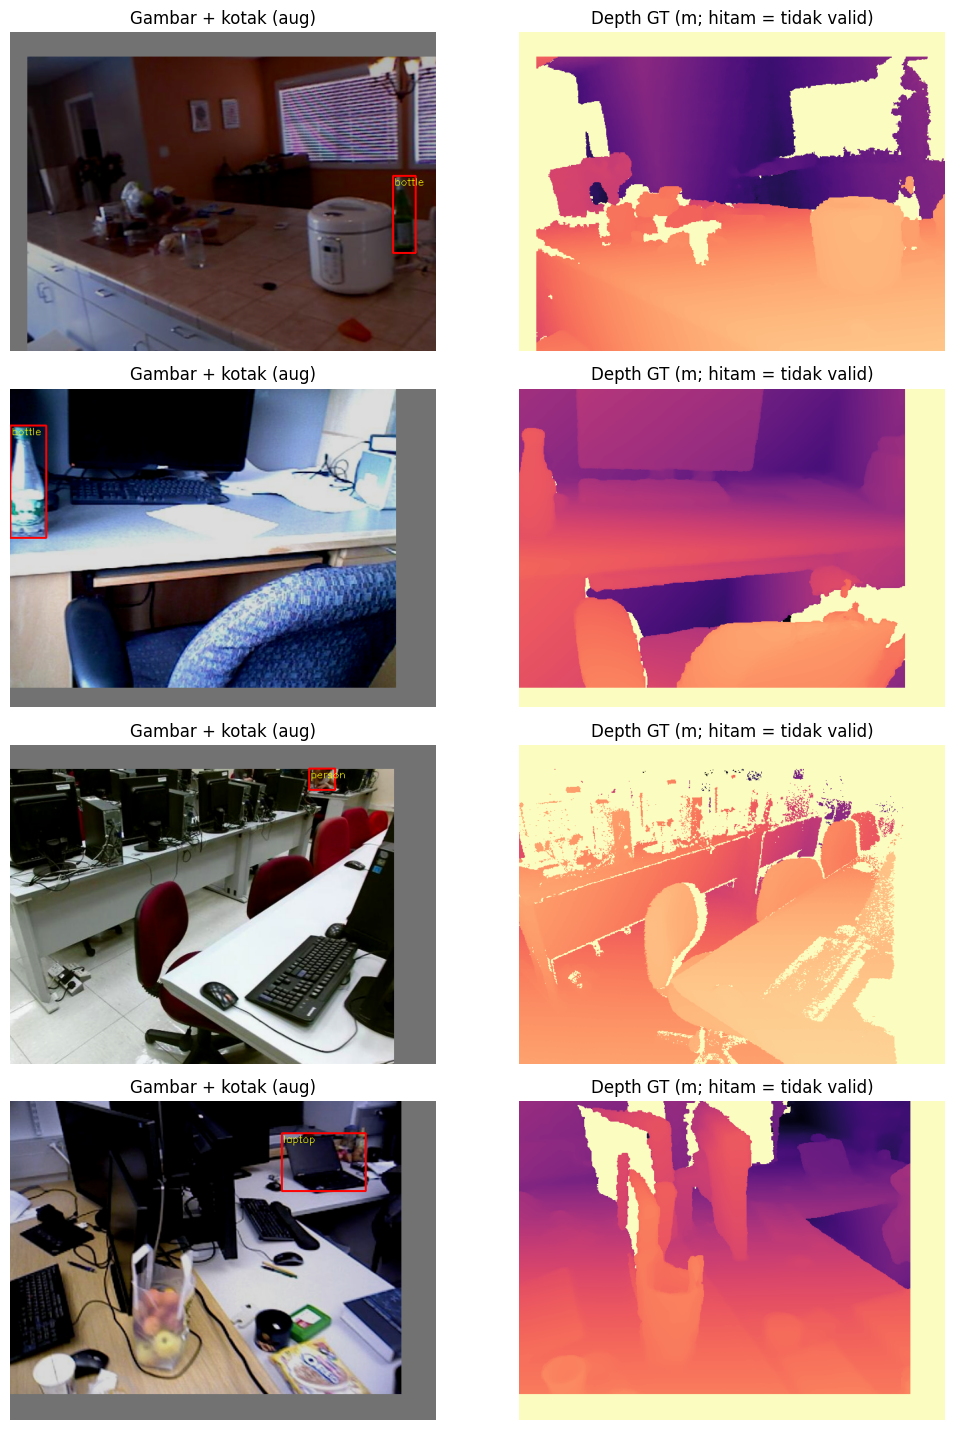

In [ ]:
ds_vis = MTDataset(train_recs, True)
pick = [i for i in range(min(len(ds_vis), 200)) if len(train_recs[i]["cls"]) > 0][:4]
fig, ax = plt.subplots(len(pick), 2, figsize=(11, 3.6 * len(pick))); ax = np.atleast_2d(ax)
for row, i in enumerate(pick):
    im, dp, cl, bb = ds_vis[i]; im = np.ascontiguousarray(im.permute(1, 2, 0).numpy())
    for (cx, cy, w, h), c in zip(bb.numpy(), cl.numpy().ravel().astype(int)):
        p1, p2 = (int((cx - w / 2) * IMG_W), int((cy - h / 2) * IMG_H)), (int((cx + w / 2) * IMG_W), int((cy + h / 2) * IMG_H))
        cv2.rectangle(im, p1, p2, (255, 0, 0), 2); cv2.putText(im, NAMES[c], (p1[0] + 2, p1[1] + 14), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 1)
    ax[row, 0].imshow(im); ax[row, 0].set_title("Gambar + kotak (aug)"); ax[row, 0].axis("off")
    ax[row, 1].imshow(dp.numpy(), cmap="magma_r"); ax[row, 1].set_title("Depth GT (m; hitam = tidak valid)"); ax[row, 1].axis("off")
plt.tight_layout(); plt.show()

## 8. Model multi-task
Sama dengan notebook lama: `DetectionModel` YOLO26n (bobot awal COCO, lapisan yang bentuknya cocok) + head `Depth` Ultralytics pada fitur P3/P4/P5 yang sama. Tambahan opsional: `DEPTH_FEAT_GRAD` mengecilkan gradien depth yang masuk ke backbone/neck (default 1.0 = perilaku lama; hanya aktif saat training, tidak memengaruhi ONNX).

In [ ]:
hyp = get_cfg(DEFAULT_CFG)
hyp.dlam, hyp.dlog, hyp.dgrad, hyp.epochs = DLAM, DEPTH_SILOG_W, DEPTH_GRAD_W, EPOCHS

def run_features(det, x):
    # backbone + neck -> fitur yang dibaca head deteksi (P3, P4, P5)
    y = []
    for m in det.model[:-1]:
        if m.f != -1: x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
        x = m(x); y.append(x if m.i in det.save else None)
    return [x if j == -1 else y[j] for j in det.model[-1].f]

class _GradScale(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, s): ctx.s = s; return x.view_as(x)
    @staticmethod
    def backward(ctx, g): return g * ctx.s, None

class MultiTask(nn.Module):
    def __init__(self, det, c_mid=256, depth_feat_grad=1.0):
        super().__init__()
        self.det, self.depth_feat_grad = det, float(depth_feat_grad)
        was = det.training; det.eval()
        with torch.no_grad(): chs = [f.shape[1] for f in run_features(det, torch.zeros(1, 3, 64, 64))]
        det.train(was); self.depth = Depth(c_mid=c_mid, ch=chs)
    def forward(self, x):
        f = run_features(self.det, x)
        fd = [_GradScale.apply(t, self.depth_feat_grad) for t in f] if (self.training and self.depth_feat_grad != 1.0) else f
        return self.det.model[-1](f), self.depth(fd)

_SRC_MODEL = None
def build_model(pretrained=True):
    # Struktur WAJIB identik di semua pemanggilan: det.load() membangun ulang cabang cls head pada lebar model sumber (80, bukan 64),
    # sehingga model tanpa det.load() tidak bisa memuat state_dict model yang dilatih. pretrained=False tetap memuat struktur yang sama;
    # bobotnya lalu ditimpa oleh load_state_dict di pemanggil.
    global _SRC_MODEL
    det = DetectionModel("yolo26n.yaml", nc=NC, verbose=False)
    if _SRC_MODEL is None: _SRC_MODEL = YOLO("yolo26n.pt").model
    det.load(copy.deepcopy(_SRC_MODEL), verbose=pretrained)
    det.args = hyp; det.names = {i: n for i, n in enumerate(NAMES)}
    det.model[-1].end2end = True                            # inferensi NMS-free; training tetap dual-head
    return MultiTask(det, depth_feat_grad=DEPTH_FEAT_GRAD).to(DEVICE)

_m = build_model(); print("Parameter:", round(sum(p.numel() for p in _m.parameters()) / 1e6, 2), "juta | head depth:", round(sum(p.numel() for p in _m.depth.parameters()) / 1e6, 2), "juta")
del _m

Overriding model.yaml nc=80 with nc=4
Transferred 696/708 items from pretrained weights
Parameter: 5.45 juta | head depth: 2.91 juta


## 9. Checkpoint atomik, evaluasi, dan validator mAP
- `atomic_save`: tulis ke file lokal sementara -> muat ulang & verifikasi -> salin ke tujuan sebagai `.tmp` -> cek ukuran -> `os.replace`. `last.pt` lama dipindah ke `last.pt.prev` (bukan dihapus) sebelum diganti.
- `last.pt` = state training penuh untuk resume (JANGAN dipakai untuk inference). `best_*.pt` = bobot EMA saja.
- Metrik depth: AbsRel/RMSE/delta1 per piksel pada piksel valid GT (> 0,001 m, <= `DEPTH_MAX_M`), dalam meter, di ruang letterbox. mAP: validator resmi Ultralytics.

In [ ]:
def atomic_json(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f: json.dump(obj, f, indent=1, ensure_ascii=False, default=str)
    os.replace(tmp, path)

def atomic_save(obj, path, required, keep_prev=False):
    tmp_local = os.path.join(WORK, "_tmp_" + os.path.basename(path))
    torch.save(obj, tmp_local)
    chk = torch.load(tmp_local, map_location="cpu", weights_only=False)
    missing = [k for k in required if k not in chk]; del chk
    if missing: raise IOError(f"checkpoint sementara tidak lengkap: {missing}")
    dst_tmp = path + ".tmp"
    shutil.copyfile(tmp_local, dst_tmp)
    if os.path.getsize(dst_tmp) != os.path.getsize(tmp_local): raise IOError("ukuran salinan checkpoint tidak cocok")
    if keep_prev and os.path.exists(path): os.replace(path, path + ".prev")
    os.replace(dst_tmp, path); os.remove(tmp_local)

FULL_KEYS = ("model", "ema", "ema_updates", "opt", "sched", "scaler", "epoch", "step", "history", "best", "bad_epochs", "config", "names", "split_sig", "run_id", "crit", "rng")
SLIM_KEYS = ("ema", "epoch", "metrics", "config", "names", "imgsz", "run_id", "kind")
P_LAST, P_STATUS, P_HIST, P_BEST = (os.path.join(CKPT_DIR, "last.pt"), os.path.join(EXP_DIR, "status.json"),
                                    os.path.join(EXP_DIR, "history.csv"), os.path.join(EXP_DIR, "best_registry.json"))
def P_SEL(kind): return os.path.join(CKPT_DIR, f"best_{kind}.pt")

def load_ckpt(path, required):
    if not os.path.exists(path): return None, "tidak ada"
    try:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        miss = [k for k in required if k not in ck]
        return (None, f"kunci hilang {miss}") if miss else (ck, "ok")
    except Exception as e:
        return None, f"gagal dibaca: {repr(e)[:150]}"

def read_status():
    try: return json.load(open(P_STATUS))
    except Exception: return None

def checkpoint_report():
    print(f"Folder checkpoint: {CKPT_DIR}")
    for p in (P_LAST, P_LAST + ".prev", P_SEL("depth"), P_SEL("det"), P_SEL("balanced")):
        req = FULL_KEYS if "last" in p else SLIM_KEYS
        ck, why = load_ckpt(p, req)
        print(f"  {os.path.basename(p):18s}", f"VALID epoch {ck['epoch']} (run {ck['run_id']})" if ck else why)
    print("  status:", read_status())
checkpoint_report()

Folder checkpoint: /content/work/persist/coco4_v1/ckpt
  last.pt            tidak ada
  last.pt.prev       tidak ada
  best_depth.pt      tidak ada
  best_det.pt        tidak ada
  best_balanced.pt   tidak ada
  status: None


In [ ]:
def save_det_ckpt(m, path):
    # bagian deteksi sebagai checkpoint Ultralytics biasa (YOLO(path).val/predict)
    d = copy.deepcopy(m.det).float(); d.criterion = None; d.model[-1].end2end = True
    torch.save({"model": d.half().eval(), "train_args": {}}, path)

def det_map(m, yaml_path, tag="tmp", per_class=False):
    p = f"{WORK}/det_{tag}.pt"; save_det_ckpt(m, p)
    r = YOLO(p).val(data=yaml_path, imgsz=max(IMG_H, IMG_W), batch=BATCH, device=DEVICE_ARG, workers=NUM_WORKERS, plots=False, verbose=False)
    out = dict(map5095=float(r.box.map), map50=float(r.box.map50), precision=float(r.box.mp), recall=float(r.box.mr))
    if per_class:
        try:
            ap = np.asarray(r.box.ap); idx = [int(i) for i in r.box.ap_class_index]
            out["per_class"] = {NAMES[i]: dict(ap50=float(ap[j, 0]), ap5095=float(ap[j].mean())) for j, i in enumerate(idx)}
        except Exception as e: out["per_class_error"] = repr(e)[:200]
    return out

def box_stats(dep_pred, dep_gt, x1, y1, x2, y2):
    x1, y1, x2, y2 = max(int(x1), 0), max(int(y1), 0), min(int(x2), IMG_W), min(int(y2), IMG_H)
    if x2 - x1 < 4 or y2 - y1 < 4: return None
    g, p = dep_gt[y1:y2, x1:x2], dep_pred[y1:y2, x1:x2]; v = g > 0.001
    if int(v.sum()) < 50: return None
    return float(g[v].median()), float(p[v].median())

@torch.no_grad()
def evaluate(m, loader, n_samples=3000, conf=0.25, max_batches=None):
    m.eval(); acc = dict(absrel=0.0, se=0.0, d1=0.0, n=0, nonfinite=0); img_abs = []; P, G = [], []; obj = {"gt": [], "pred": []}
    for bi_, batch in enumerate(loader):
        if max_batches is not None and bi_ >= max_batches: break
        img = batch["img"].to(DEVICE).float() / 255
        det_out, dep = m(img)
        dets = det_out[0] if isinstance(det_out, (tuple, list)) else det_out
        dep = F.interpolate(dep.float(), size=(IMG_H, IMG_W), mode="bilinear", align_corners=True)[:, 0]
        acc["nonfinite"] += int((~torch.isfinite(dep)).sum()); dep = torch.nan_to_num(dep, nan=1.0, posinf=DEPTH_MAX_M, neginf=1e-3)
        gt = batch["depth"].to(DEVICE); valid = gt > 0.001
        p, g = dep[valid], gt[valid]
        acc["absrel"] += float(((p - g).abs() / g).sum()); acc["se"] += float(((p - g) ** 2).sum())
        acc["d1"] += float((torch.max(p / g, g / p.clamp(min=1e-6)) < 1.25).float().sum()); acc["n"] += int(g.numel())
        for b in range(len(gt)):
            pb, gb = dep[b][valid[b]], gt[b][valid[b]]
            if len(pb) == 0: continue
            img_abs.append(float(((pb - gb).abs() / gb).mean()))
            sel = torch.randperm(len(pb), device=pb.device)[:n_samples]; P.append(pb[sel].cpu().numpy()); G.append(gb[sel].cpu().numpy())
            d = dets[b]; d = d[d[:, 4] >= conf]
            for row in d.tolist():
                s = box_stats(dep[b], gt[b], *row[:4])
                if s: obj["pred"].append((*s, int(row[5])))
        bi, bb, cc = batch["batch_idx"].long(), batch["bboxes"], batch["cls"].view(-1)
        for j in range(len(bi)):
            cx, cy, w, h = bb[j].tolist()
            s = box_stats(dep[int(bi[j])], gt[int(bi[j])], (cx - w / 2) * IMG_W, (cy - h / 2) * IMG_H, (cx + w / 2) * IMG_W, (cy + h / 2) * IMG_H)
            if s: obj["gt"].append((*s, int(cc[j])))
    n = max(acc["n"], 1)
    return dict(absrel=acc["absrel"] / n, absrel_img=float(np.mean(img_abs)) if img_abs else float("nan"), rmse=math.sqrt(acc["se"] / n), d1=acc["d1"] / n,
                nonfinite=acc["nonfinite"], P=np.concatenate(P) if P else np.zeros(0), G=np.concatenate(G) if G else np.zeros(0),
                obj={k: np.array(v).reshape(-1, 3) for k, v in obj.items()})

def range_table(P, G):
    rows = []
    for lo, hi in [(0, 1), (1, 2), (2, 4), (4, DEPTH_MAX_M + 0.01)]:
        mk = (G >= lo) & (G < hi)
        if mk.sum() == 0: continue
        e = np.abs(P[mk] - G[mk])
        rows.append({"rentang GT (m)": f"{lo}-{min(hi, DEPTH_MAX_M):g}", "piksel": int(mk.sum()), "MAE (m)": round(float(e.mean()), 3),
                     "AbsRel": round(float((e / G[mk]).mean()), 3), "bias pred-gt (m)": round(float((P[mk] - G[mk]).mean()), 3)})
    return pd.DataFrame(rows)

def obj_summary(o):
    if len(o) == 0: return None
    g, p = o[:, 0], o[:, 1]; e = np.abs(p - g)
    return dict(n=int(len(o)), mae_m=float(e.mean()), median_err_m=float(np.median(e)), absrel=float(np.mean(e / g)), within20=float(np.mean(e / g < 0.2)))

def per_class_depth(o):
    out = {}
    for c in sorted(set(o[:, 2].astype(int))):
        s = obj_summary(o[o[:, 2] == c])
        if s: out[NAMES[c]] = s
    return out

def load_model_from_ckpt(path):
    ck, why = load_ckpt(path, SLIM_KEYS)
    assert ck is not None, f"{path}: {why}"
    m = build_model(pretrained=False); m.load_state_dict(ck["ema"], strict=True); m.eval()
    return m, ck
print("Fungsi checkpoint/evaluasi siap.")

Fungsi checkpoint/evaluasi siap.


## 10. Loop training
Urutan per langkah: forward (AMP) -> loss (deteksi + `LAMBDA_DEPTH` x depth) -> cek finite -> `scaler.scale().backward()` -> `unscale_` -> clip -> `scaler.step` -> `scaler.update` -> **hanya bila optimizer benar-benar melangkah**: `sched.step()` dan `ema.update()`. Langkah yang dilewati GradScaler (overflow fp16) dihitung dan dicatat.
Setelah tiap epoch: evaluasi EMA pada val dan pada subset train (diagnosis overfit), pembaruan checkpoint terbaik, penyimpanan `last.pt` atomik, `history.csv`, `status.json`.

In [ ]:
BETTER = {"absrel": "min", "rmse": "min", "d1": "max", "map50": "max", "map5095": "max", "balanced": "max"}
ROWKEY = lambda m: m if m == "balanced" else "val_" + m
SEL = {"depth": "absrel", "det": "map5095", "balanced": "balanced"}      # checkpoint -> metrik penentu
ES_SETS = {"balanced": {"balanced"}, "depth": {"absrel"}, "det": {"map5095"}, "any": {"absrel", "map5095"}}
MIN_DELTA = 1e-4

def balanced_ref(history):
    # 30 kelas default: acuan = baseline lama. Set kelas khusus: baseline tidak setara -> acuan = metrik val epoch pertama run ini
    if CLASSES is None: return BASELINE["map5095"], BASELINE["absrel"]
    for h in history:
        if h.get("val_map5095", 0) > 1e-3 and h.get("val_absrel", 0) > 1e-6: return h["val_map5095"], h["val_absrel"]
    return None

def balanced_score(map5095, absrel, history=()):
    ref = balanced_ref(history) or (max(map5095, 1e-3), absrel)
    return BALANCE_W_DET * (map5095 / ref[0]) + (1 - BALANCE_W_DET) * (ref[1] / max(absrel, 1e-6))

def split_param_groups(mt):
    last = len(mt.det.model) - 1
    g = {"backbone": ([], []), "det_head": ([], []), "depth": ([], [])}
    for n, p in mt.named_parameters():
        if not p.requires_grad: continue
        k = "depth" if n.startswith("depth.") else ("det_head" if n.startswith(f"det.model.{last}.") else "backbone")
        g[k][0 if p.ndim > 1 else 1].append(p)
    lr = {"backbone": LR_BACKBONE, "det_head": LR_DET_HEAD, "depth": LR_DEPTH}
    groups = []
    for k, (dec, nodec) in g.items():
        if dec: groups.append({"params": dec, "lr": lr[k], "weight_decay": WEIGHT_DECAY, "name": k + "_decay"})
        if nodec: groups.append({"params": nodec, "lr": lr[k], "weight_decay": 0.0, "name": k + "_nodecay"})
    return groups

def compat_check(ck):
    diffs = [f"{k}: ckpt={ck['config'].get(k)} sekarang={CFG.get(k)}" for k in MUST_MATCH if ck["config"].get(k) != CFG.get(k)]
    if ck["names"] != NAMES: diffs.append("daftar kelas berbeda")
    if ck["split_sig"] != SPLIT_SIG: diffs.append(f"split data berbeda ({ck['split_sig']} vs {SPLIT_SIG})")
    return diffs

def archive_old_run():
    ts = time.strftime("%Y%m%d-%H%M%S"); dst = os.path.join(EXP_DIR, f"archive_{ts}"); os.makedirs(dst)
    for p in (CKPT_DIR, ART_DIR, P_STATUS, P_HIST, P_BEST):
        if os.path.exists(p): shutil.move(p, dst)
    os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(ART_DIR, exist_ok=True)
    print("Run lama diarsipkan ke", dst)

def run_training():
    st = read_status()
    ck_path_ok = None
    if RESUME == "never" and (os.path.exists(P_LAST) or st): archive_old_run(); st = None
    ck = None
    if RESUME in ("auto", "force"):
        for cand in (P_LAST, P_LAST + ".prev"):
            c, why = load_ckpt(cand, FULL_KEYS)
            if c is None:
                if os.path.exists(cand): print(f"  {os.path.basename(cand)} tidak bisa dipakai: {why}")
                continue
            diffs = compat_check(c)
            if diffs and RESUME != "force":
                raise RuntimeError("Checkpoint tidak cocok dengan konfigurasi sekarang (RESUME='force' untuk memaksa, atau 'never' untuk mulai baru):\n  " + "\n  ".join(diffs))
            ck, ck_path_ok = c, cand; break
    mt = build_model(pretrained=ck is None)
    depth_crit = DepthLoss26(mt.det)
    ema = ModelEMA(mt, decay=EMA_DECAY, tau=EMA_TAU)
    opt = torch.optim.AdamW(split_param_groups(mt), lr=LR_BACKBONE)
    total_it = EPOCHS * len(train_dl); warm = max(1, min(WARMUP_ITERS, total_it // 10))
    def lr_lambda(it):
        if it < warm: return (it + 1) / warm
        p = (it - warm) / max(1, total_it - warm)
        return LR_FINAL_FRAC + (1 - LR_FINAL_FRAC) * 0.5 * (1 + math.cos(math.pi * p))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
    crit = mt.det.criterion = mt.det.init_criterion()          # dibuat di awal agar state-nya bisa dipulihkan
    state = dict(epoch=0, step=0, history=[], best={}, bad_epochs=0, run_id=time.strftime("%Y%m%d-%H%M%S") + "-" + uuid.uuid4().hex[:6])
    if ck is not None:
        mt.load_state_dict(ck["model"]); ema.ema.load_state_dict(ck["ema"]); ema.updates = ck["ema_updates"]
        opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        for k, v in ck["crit"].items(): setattr(crit, k, v)
        state.update(epoch=ck["epoch"], step=ck["step"], history=list(ck["history"]), best=dict(ck["best"]), bad_epochs=ck["bad_epochs"], run_id=ck["run_id"])
        try:
            random.setstate(ck["rng"]["py"]); np.random.set_state(ck["rng"]["np"]); torch.set_rng_state(ck["rng"]["torch"].cpu())
            if ck["rng"].get("cuda") is not None and AMP: torch.cuda.set_rng_state_all([t.cpu() for t in ck["rng"]["cuda"]])
        except Exception as e: print("RNG tidak sepenuhnya dipulihkan:", repr(e)[:100])
        print(f"RESUME dari {os.path.basename(ck_path_ok)}: epoch {state['epoch']} selesai, lanjut epoch {state['epoch'] + 1}/{EPOCHS} (langkah {state['step']}, run {state['run_id']})")
        del ck
    else:
        print("Mulai training BARU, run", state["run_id"])
    if state["epoch"] >= EPOCHS:
        print("Training sudah mencapai EPOCHS."); return state

    def status(s, **kw): atomic_json(dict(run_id=state["run_id"], status=s, epoch=state["epoch"], epochs=EPOCHS, smoke=SMOKE_TEST, experiment=EXPERIMENT,
                                          updated=time.strftime("%Y-%m-%d %H:%M:%S"), **kw), P_STATUS)
    def full_ckpt():
        return dict(model=mt.state_dict(), ema=ema.ema.state_dict(), ema_updates=ema.updates, opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict(),
                    epoch=state["epoch"], step=state["step"], history=state["history"], best=state["best"], bad_epochs=state["bad_epochs"], config=CFG, names=NAMES,
                    split_sig=SPLIT_SIG, run_id=state["run_id"], crit={k: getattr(crit, k) for k in ("updates", "o2m", "o2o") if hasattr(crit, k)},
                    rng=dict(py=random.getstate(), np=np.random.get_state(), torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all() if AMP else None),
                    versions=dict(torch=torch.__version__, ultralytics=ultralytics.__version__))
    def slim(kind, row):
        return dict(ema=ema.ema.state_dict(), epoch=state["epoch"], metrics=row, config=CFG, names=NAMES, imgsz=(IMG_H, IMG_W), run_id=state["run_id"], kind=kind)

    params = [p for g in opt.param_groups for p in g["params"]]
    t_start = time.time(); status("running"); stop_reason = "completed"
    try:
        for ep in range(state["epoch"] + 1, EPOCHS + 1):
            _g.manual_seed(SEED + ep)                              # urutan data per epoch reprodusibel (juga setelah resume)
            mt.train(); t0 = time.time(); agg, nb, n_skip, n_nonfin, gn_sum, n_clip = {}, 0, 0, 0, 0.0, 0
            for batch in tqdm(train_dl, desc=f"epoch {ep}/{EPOCHS}", leave=False):
                batch = {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}; batch["img"] = batch["img"].float() / 255
                with torch.autocast(device_type=DEVICE, enabled=AMP):
                    det_out, dep_out = mt(batch["img"])
                    l_det, it_det = mt.det.loss(batch, det_out)
                    l_dep, it_dep = depth_crit(dep_out, batch)
                    loss = l_det.sum() + LAMBDA_DEPTH * l_dep.sum()
                opt.zero_grad(set_to_none=True)
                if not torch.isfinite(loss): n_nonfin += 1; continue
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                gn = torch.nn.utils.clip_grad_norm_(params, GRAD_CLIP)
                before = scaler.get_scale(); scaler.step(opt); scaler.update()
                if scaler.get_scale() < before: n_skip += 1; continue          # overflow fp16: optimizer dilewati -> scheduler/EMA tidak maju
                sched.step(); ema.update(mt); state["step"] += 1; nb += 1
                for k, v in {**it_det, **it_dep}.items(): agg[k] = agg.get(k, 0.0) + v.detach().float()
                gn_sum = gn_sum + gn.detach().float(); n_clip = n_clip + (gn.detach() > GRAD_CLIP).float()
            if hasattr(crit, "update"): crit.update()                # jadwal bobot one-to-many -> one-to-one (per epoch)
            state["epoch"] = ep
            r = evaluate(ema.ema, val_dl); rp = evaluate(ema.ema, probe_dl)
            row = dict(epoch=ep, **{k: float(v) / max(nb, 1) for k, v in agg.items()}, grad_norm=float(gn_sum) / max(nb, 1), clip_frac=float(n_clip) / max(nb, 1),
                       skipped_overflow=n_skip, skipped_nonfinite=n_nonfin, lr_backbone=opt.param_groups[0]["lr"], lr_depth=[g["lr"] for g in opt.param_groups if g["name"].startswith("depth")][0],
                       val_absrel=r["absrel"], val_absrel_img=r["absrel_img"], val_rmse=r["rmse"], val_d1=r["d1"], probe_absrel=rp["absrel"], probe_rmse=rp["rmse"], probe_d1=rp["d1"])
            if ep % DET_EVAL_EVERY == 0 or ep == EPOCHS:
                dv, dp = det_map(ema.ema, YAML["val"], "val"), det_map(ema.ema, YAML["probe"], "probe")
                row.update(val_map5095=dv["map5095"], val_map50=dv["map50"], val_precision=dv["precision"], val_recall=dv["recall"], probe_map5095=dp["map5095"], probe_map50=dp["map50"])
                row["balanced"] = balanced_score(dv["map5095"], r["absrel"], state["history"])
            # --- catat terbaik per metrik + simpan checkpoint terbaik ---
            improved = set()
            for m_, mode in BETTER.items():
                v = row.get(ROWKEY(m_))
                if v is None or not np.isfinite(v): continue
                cur = state["best"].get(m_)
                if cur is None or (v < cur["value"] - MIN_DELTA if mode == "min" else v > cur["value"] + MIN_DELTA):
                    state["best"][m_] = dict(value=float(v), epoch=ep, checkpoint=(f"best_{[k for k, mm in SEL.items() if mm == m_][0]}.pt" if m_ in SEL.values() else None)); improved.add(m_)
            for kind, m_ in SEL.items():
                if m_ in improved: atomic_save(slim(kind, row), P_SEL(kind), SLIM_KEYS)
            state["bad_epochs"] = 0 if (improved & ES_SETS[EARLY_STOP_METRIC]) else state["bad_epochs"] + 1
            state["history"].append(row)
            row["bad_epochs"] = state["bad_epochs"]
            print(f"ep {ep:02d}/{EPOCHS} | " + " | ".join(f"{k} {v:.4f}" for k, v in row.items() if k in ("box_loss", "cls_loss", "dlog_loss", "dgrad_loss", "val_absrel", "val_rmse", "val_d1", "val_map5095", "val_map50", "probe_map5095", "balanced"))
                  + f" | skip {n_skip} | {time.time() - t0:.0f}s | " + ("BEST: " + ",".join(sorted(improved)) if improved else f"tanpa perbaikan {state['bad_epochs']}/{PATIENCE}"))
            # --- hentikan? ---
            if state["bad_epochs"] >= PATIENCE and ep >= MIN_EPOCHS: stop_reason = "early_stopped"
            elif ep == EPOCHS: stop_reason = "completed"
            elif MAX_TRAIN_MINUTES and (time.time() - t_start) / 60 > MAX_TRAIN_MINUTES: stop_reason = "paused"
            else: stop_reason = None
            # --- simpan state (urutan: terbaik sudah tersimpan, lalu last, riwayat, status) ---
            if ep % SAVE_EVERY == 0 or stop_reason: atomic_save(full_ckpt(), P_LAST, FULL_KEYS, keep_prev=True)
            tmp = P_HIST + ".tmp"; pd.DataFrame(state["history"]).to_csv(tmp, index=False); os.replace(tmp, P_HIST)
            atomic_json(state["best"], P_BEST)
            status(stop_reason or "running", best=state["best"])
            if stop_reason: break
    except KeyboardInterrupt:
        stop_reason = "interrupted"; status("interrupted", best=state["best"]); print("Dihentikan manual; checkpoint terakhir yang valid tetap aman. Jalankan sel ini lagi untuk resume.")
    except Exception:
        status("failed", error=traceback.format_exc()[-1500:]); raise
    print(f"Selesai: {stop_reason} pada epoch {state['epoch']}. Terbaik per metrik:")
    for k, v in state["best"].items(): print(f"  {k:9s} {v['value']:.4f} @ epoch {v['epoch']}  ckpt: {v['checkpoint'] or '(hanya dicatat)'}")
    mt = ema = opt = None; torch.cuda.empty_cache()
    return state
print("run_training() siap.")

run_training() siap.


## 11. Pre-flight (uji singkat, tidak melatih)
Memeriksa: 1 langkah training AMP (loss/gradien finite), siklus simpan-muat checkpoint atomik, evaluasi mini, dan validator mAP. Aman dijalankan kapan saja.

In [ ]:
def preflight():
    mt = build_model(); mt.train(); crit_d = DepthLoss26(mt.det); mt.det.criterion = mt.det.init_criterion()
    opt = torch.optim.AdamW(split_param_groups(mt)); scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
    batch = {k: v.to(DEVICE) for k, v in next(iter(train_dl)).items()}; batch["img"] = batch["img"].float() / 255
    torch.cuda.reset_peak_memory_stats() if AMP else None
    n_skip, gn = 0, float("nan")
    for attempt in range(10):          # GradScaler mulai dari skala 65536: beberapa langkah awal dilewati karena overflow fp16 (normal)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE, enabled=AMP):
            det_out, dep_out = mt(batch["img"]); l_det, it_det = mt.det.loss(batch, det_out); l_dep, it_dep = crit_d(dep_out, batch)
            loss = l_det.sum() + LAMBDA_DEPTH * l_dep.sum()
        assert torch.isfinite(loss), "loss tidak finite (masalah pada data/model, bukan scaler)"
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        gn = float(torch.nn.utils.clip_grad_norm_(mt.parameters(), GRAD_CLIP))
        before = scaler.get_scale(); scaler.step(opt); scaler.update()
        if scaler.get_scale() < before or not math.isfinite(gn): n_skip += 1; continue
        break
    assert math.isfinite(gn), f"gradien tetap tidak finite setelah {n_skip} percobaan: ada masalah nyata"
    print(f"    langkah dilewati karena overflow AMP sebelum langkah sukses: {n_skip} (normal bila kecil)")
    dep_head_grad = sum(float(p.grad.abs().sum()) for p in mt.depth.parameters() if p.grad is not None)
    print(f"[1] langkah training OK | loss {float(loss.detach()):.3f} | deteksi {{{', '.join(f'{k} {float(v):.3f}' for k, v in it_det.items())}}} | depth {{{', '.join(f'{k} {float(v):.3f}' for k, v in it_dep.items())}}} | grad_norm {gn:.2f} | grad head depth {dep_head_grad:.2e}")
    if AMP: print(f"    memori GPU puncak: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB (batch {BATCH})")
    # siklus checkpoint atomik
    tp = os.path.join(WORK, "preflight.pt"); sd = {k: v.detach().cpu().clone() for k, v in mt.state_dict().items()}
    atomic_save(dict(ema=mt.state_dict(), epoch=0, metrics={}, config=CFG, names=NAMES, imgsz=(IMG_H, IMG_W), run_id="preflight", kind="preflight"), tp, SLIM_KEYS)
    ck, why = load_ckpt(tp, SLIM_KEYS); assert ck is not None, why
    assert all(torch.equal(sd[k], ck["ema"][k].cpu()) for k in sd), "bobot hasil muat != bobot disimpan"
    m2 = build_model(pretrained=False); m2.load_state_dict(ck["ema"], strict=True); os.remove(tp)
    print("[2] simpan/muat checkpoint atomik OK, arsitektur direkonstruksi OK")
    ev = evaluate(m2, val_dl, max_batches=2)
    assert all(math.isfinite(ev[k]) for k in ("absrel", "rmse", "d1")), "metrik depth tidak finite"
    print(f"[3] evaluasi mini OK (bobot acak, angka tidak bermakna): AbsRel {ev['absrel']:.3f} RMSE {ev['rmse']:.3f}")
    dm = det_map(m2, YAML["probe"], "pre"); print(f"[4] validator mAP berjalan OK (mAP50 {dm['map50']:.4f}, tidak bermakna)")
    del mt, m2, opt; torch.cuda.empty_cache(); print("PRE-FLIGHT LULUS")
if RUN_PREFLIGHT: preflight()
else: print("Pre-flight dilewati (RUN_PREFLIGHT=False).")

Overriding model.yaml nc=80 with nc=4
Transferred 696/708 items from pretrained weights


## 12. Jalankan training (harus disengaja)
Sel ini tidak melatih kecuali `CONFIRM_TRAIN = True`. Jika `ckpt/last.pt` valid ditemukan, training otomatis dilanjutkan. Jika training sudah selesai, sel ini dilewati.

In [ ]:
_st = read_status()
checkpoint_report()
if _st and _st.get("status") in ("completed", "early_stopped") and RESUME != "never":
    print(f"\nTraining untuk eksperimen ini sudah selesai ({_st['status']}, epoch {_st['epoch']}). Lanjut ke sel evaluasi. (RESUME='never' untuk mengulang dari awal.)")
elif not CONFIRM_TRAIN:
    print("\nTRAINING TIDAK DIJALANKAN: CONFIRM_TRAIN = False. Periksa konfigurasi di atas; set CONFIRM_TRAIN = True di sel konfigurasi (jalankan ulang sel itu) lalu jalankan sel ini.")
else:
    TRAIN_STATE = run_training()

## 13. Evaluasi akhir semua checkpoint terbaik (val dan test), kalibrasi depth, laporan
- Tiap checkpoint (`best_balanced`, `best_depth`, `best_det`, `last`) dievaluasi pada **val** dan **test** (test tidak pernah dipakai untuk keputusan apa pun).
- **Kalibrasi skala depth** untuk checkpoint yang diekspor: regresi log-log pada 500 gambar *train* (tanpa augmentasi). Diterima hanya bila `a` masuk akal (0,3-3) dan RMSE val tidak memburuk. **Risiko:** keputusan terima/tolak memakai val (satu keputusan biner, dua parameter), sehingga val sedikit optimistis untuk langkah ini; angka test tidak terpengaruh.
- Sel ini menghapus isi `artifacts/` lama lebih dulu agar tidak ada berkas basi yang ikut terkemas.

In [ ]:
EVAL_ERRORS = []
_st = read_status()
assert _st is not None, "Belum ada status training. Jalankan training dulu."
RUN_ID = _st["run_id"]
shutil.rmtree(ART_DIR, ignore_errors=True); os.makedirs(ART_DIR, exist_ok=True)

@torch.no_grad()
def fit_calibration(m, loader, n_samples=3000):
    m.eval(); old = (m.depth.cal_a.clone(), m.depth.cal_b.clone()); m.depth.cal_a.fill_(1.0); m.depth.cal_b.zero_(); P, G = [], []
    for batch in loader:
        _, dep = m(batch["img"].to(DEVICE).float() / 255)
        dep = F.interpolate(dep.float(), size=(IMG_H, IMG_W), mode="bilinear", align_corners=True)[:, 0]
        gt = batch["depth"].to(DEVICE); valid = gt > 0.001
        for b in range(len(gt)):
            pb, gb = dep[b][valid[b]], gt[b][valid[b]]; sel = torch.randperm(len(pb), device=pb.device)[:n_samples]
            P.append(pb[sel].cpu().numpy()); G.append(gb[sel].cpu().numpy())
    P, G = np.concatenate(P), np.concatenate(G)
    A = np.stack([np.log(np.clip(P, 1e-3, None)), np.ones_like(P)], 1)
    a, b = np.linalg.lstsq(A, np.log(np.clip(G, 1e-3, None)), rcond=None)[0]
    m.depth.cal_a.fill_(float(a)); m.depth.cal_b.fill_(float(b))
    return old, float(a), float(b)

def eval_model(m, tag):
    out = {}
    for split, dl in (("val", val_dl), ("test", test_dl)):
        if dl is None: continue
        r = evaluate(m, dl); d = det_map(m, YAML[split], f"{tag}_{split}", per_class=True)
        out[split] = dict(depth=dict(absrel=r["absrel"], absrel_per_image=r["absrel_img"], rmse_m=r["rmse"], delta1=r["d1"], nonfinite_pred=r["nonfinite"]),
                          detection=d, object_depth_gt_boxes=obj_summary(r["obj"]["gt"]), object_depth_pred_boxes=obj_summary(r["obj"]["pred"]),
                          object_depth_per_class=per_class_depth(r["obj"]["gt"]), depth_by_range=range_table(r["P"], r["G"]).to_dict("records"))
    return out

REPORT = dict(run_id=RUN_ID, training_status=_st["status"], epochs_done=_st["epoch"], smoke=SMOKE_TEST, experiment=EXPERIMENT, baseline_val_from_old_notebook=BASELINE,
              split=dict(mode=SPLIT_MODE, sig=SPLIT_SIG, n_train=len(train_recs), n_val=len(val_recs), n_test=len(test_recs)), leak_audit=LEAK, checkpoints={})
CKPT_PATHS = {"balanced": P_SEL("balanced"), "depth": P_SEL("depth"), "det": P_SEL("det"), "last_ema": P_LAST}
for name, path in CKPT_PATHS.items():
    try:
        if name == "last_ema":
            ck, why = load_ckpt(path, FULL_KEYS); assert ck is not None, why
            m = build_model(pretrained=False); m.load_state_dict(ck["ema"], strict=True); ep_ = ck["epoch"]; rid = ck["run_id"]; del ck
        else:
            m, ck = load_model_from_ckpt(path); ep_, rid = ck["epoch"], ck["run_id"]; del ck
        assert rid == RUN_ID, f"run_id checkpoint {rid} != status {RUN_ID} (berkas dari run lain)"
        m.eval(); xx = torch.rand(1, 3, IMG_H, IMG_W, device=DEVICE)       # forward pass dummy: bentuk dan nilai valid
        with torch.no_grad(): do, dd = m(xx)
        do = do[0] if isinstance(do, (tuple, list)) else do
        assert tuple(dd.shape[-2:]) in ((IMG_H // 4, IMG_W // 4), (IMG_H, IMG_W)) and bool(torch.isfinite(dd).all()) and bool((dd > 0).all()), f"output depth tidak valid {tuple(dd.shape)}"
        assert do.ndim == 3 and do.shape[-1] == 6 and bool(torch.isfinite(do).all()), f"output deteksi tidak valid {tuple(do.shape)}"
        REPORT["checkpoints"][name] = dict(epoch=ep_, **eval_model(m, name))
        v = REPORT["checkpoints"][name]["val"]
        print(f"{name:9s} (epoch {ep_:2d}) VAL: AbsRel {v['depth']['absrel']:.4f} RMSE {v['depth']['rmse_m']:.4f} d1 {v['depth']['delta1']:.4f} | mAP50 {v['detection']['map50']:.4f} mAP50-95 {v['detection']['map5095']:.4f}")
        del m
    except Exception as e:
        EVAL_ERRORS.append(f"eval {name}: {traceback.format_exc()}"); print(f"{name}: GAGAL dievaluasi -> {repr(e)[:200]}")

# --- kalibrasi + model final untuk ekspor ---
FINAL = dict(ok=False)
try:
    src = CKPT_PATHS[EXPORT_FROM]; fm, fck = load_model_from_ckpt(src); assert fck["run_id"] == RUN_ID
    unc_val = evaluate(fm, val_dl); cal = dict(applied=False, a=1.0, b=0.0, reason="CALIBRATE=False")
    if CALIBRATE:
        old, a, b = fit_calibration(fm, calib_dl); cal = dict(applied=True, a=a, b=b, reason="diterima")
        if not (0.3 <= a <= 3.0):
            fm.depth.cal_a.copy_(old[0]); fm.depth.cal_b.copy_(old[1]); cal = dict(applied=False, a=1.0, b=0.0, reason=f"a={a:.3f} di luar 0,3-3")
        else:
            cv_ = evaluate(fm, val_dl)
            if cv_["rmse"] > unc_val["rmse"]:
                fm.depth.cal_a.copy_(old[0]); fm.depth.cal_b.copy_(old[1]); cal = dict(applied=False, a=1.0, b=0.0, reason=f"RMSE val memburuk ({unc_val['rmse']:.4f} -> {cv_['rmse']:.4f})")
        print("Kalibrasi:", cal)
    cal["val_rmse_before"] = unc_val["rmse"]; cal["val_rmse_after"] = evaluate(fm, val_dl)["rmse"]
    FINAL_PT = os.path.join(ART_DIR, "multitask_best.pt")
    atomic_save(dict(ema=fm.state_dict(), names=NAMES, imgsz=(IMG_H, IMG_W), cal_a=float(fm.depth.cal_a), cal_b=float(fm.depth.cal_b), run_id=RUN_ID, epoch=fck["epoch"],
                     metrics=fck["metrics"], config=CFG, kind="inference_multitask", source=EXPORT_FROM), FINAL_PT, ("ema", "names", "run_id", "kind"))
    REPORT["export_model"] = dict(source=EXPORT_FROM, epoch=fck["epoch"], calibration=cal, **eval_model(fm, "final"))
    for sp in ("val", "test"):
        if sp in REPORT["export_model"]:
            e = REPORT["export_model"][sp]; print(f"MODEL EKSPOR {sp.upper():4s}: AbsRel {e['depth']['absrel']:.4f} RMSE {e['depth']['rmse_m']:.4f} d1 {e['depth']['delta1']:.4f} | mAP50 {e['detection']['map50']:.4f} mAP50-95 {e['detection']['map5095']:.4f}")
    FINAL = dict(ok=True, path=FINAL_PT, cal=cal, epoch=fck["epoch"])
    # checkpoint deteksi saja (dari best_det) agar kompatibel dengan YOLO(path)
    dm, dck = load_model_from_ckpt(CKPT_PATHS["det"]); DET_ONLY_PT = os.path.join(ART_DIR, "detection_only_best_det.pt"); save_det_ckpt(dm, DET_ONLY_PT)
    _chk = YOLO(DET_ONLY_PT); assert len(_chk.names) == NC; REPORT["det_only"] = dict(source="det", epoch=dck["epoch"]); del dm, _chk
except Exception:
    EVAL_ERRORS.append("final model: " + traceback.format_exc()); print("Model final GAGAL dibuat:\n", traceback.format_exc()[-600:])

# --- ringkasan vs baseline + laporan ---
def _cmp():
    rows = []
    for name, c in REPORT["checkpoints"].items():
        v = c["val"]; rows.append(dict(checkpoint=name, epoch=c["epoch"], absrel=v["depth"]["absrel"], rmse=v["depth"]["rmse_m"], d1=v["depth"]["delta1"], map50=v["detection"]["map50"], map5095=v["detection"]["map5095"]))
    rows.append(dict(checkpoint="BASELINE lama (30 kelas, epoch campur, split lama)" + ("" if CLASSES is None else " - TIDAK SETARA"), epoch="-", **BASELINE))
    return pd.DataFrame(rows)
cmp_df = _cmp(); print(cmp_df.round(4).to_string(index=False))
REPORT["comparison_val"] = cmp_df.to_dict("records")
REPORT["notes"] = ["Val dipakai untuk seleksi checkpoint/early stopping/keputusan kalibrasi; test hanya dilaporkan.",
                   "Perbandingan dengan baseline hanya setara bila SPLIT_MODE='legacy'; pada 'grouped' val berbeda.",
                   "Kalibrasi memakai train; keputusan terima/tolak memakai val.", "Satu seed, satu run: selisih kecil bukan bukti perbaikan."]
REPORT["eval_errors"] = EVAL_ERRORS
atomic_json(REPORT, os.path.join(ART_DIR, "eval_report.json"))
with open(os.path.join(ART_DIR, "eval_report.txt"), "w") as f:
    f.write(f"Run {RUN_ID} | status {_st['status']} | epoch {_st['epoch']} | split {SPLIT_MODE}\n\n{cmp_df.round(4).to_string(index=False)}\n\n")
    for k, v in REPORT.get("export_model", {}).items():
        if k in ("val", "test"): f.write(f"Model ekspor {k}: depth {json.dumps(v['depth'])}\n  deteksi {json.dumps({a: b for a, b in v['detection'].items() if a != 'per_class'})}\n")
    f.write("\nCatatan:\n- " + "\n- ".join(REPORT["notes"]) + "\n")
print("Laporan tersimpan di", ART_DIR)

In [ ]:
# ---- metrik per kelas (model ekspor, test bila ada, jika tidak val) ----
try:
    sp = "test" if "test" in REPORT.get("export_model", {}) else "val"; e = REPORT["export_model"][sp]
    rows = [dict(kelas=c, ap50=d.get("ap50"), ap5095=d.get("ap5095"), n_box_depth=e["object_depth_per_class"].get(c, {}).get("n"),
                 depth_absrel_objek=e["object_depth_per_class"].get(c, {}).get("absrel")) for c, d in e["detection"].get("per_class", {}).items()]
    pc = pd.DataFrame(rows).sort_values("ap5095", ascending=False); print(f"Per kelas ({sp}):"); print(pc.round(3).to_string(index=False))
    pc.to_csv(os.path.join(ART_DIR, f"per_class_{sp}.csv"), index=False)
except Exception as ex: EVAL_ERRORS.append("per-class: " + repr(ex)); print("Tabel per kelas gagal:", repr(ex)[:150])

## 13b. mAP pada val COCO (terpisah)

In [ ]:
# ---- mAP pada val COCO (terpisah dari SUN; hanya bila COCO_MIX > 0). Jalankan SETELAH sel evaluasi akhir (sel itu mengosongkan artifacts/) ----
try:
    assert coco_val_recs, "tidak ada val COCO (COCO_MIX = 0)"
    assert FINAL.get("ok"), "model ekspor belum dibuat (sel evaluasi akhir gagal/belum jalan)"
    cm, _ = load_model_from_ckpt(FINAL["path"])
    res = det_map(cm, YAML["coco_val"], "coco_val", per_class=True); del cm
    res.update(n_images=len(coco_val_recs), source=EXPORT_FROM, epoch=FINAL["epoch"], note="val2017 subset berisi kelas target; tidak sebanding dengan mAP SUN atau baseline lama")
    atomic_json(res, os.path.join(ART_DIR, "coco_val_report.json"))
    pc = pd.DataFrame([dict(kelas=c, ap50=d["ap50"], ap5095=d["ap5095"]) for c, d in res.get("per_class", {}).items()])
    if len(pc): pc.to_csv(os.path.join(ART_DIR, "per_class_coco_val.csv"), index=False)
    print(f"COCO val ({len(coco_val_recs)} gambar): mAP50 {res['map50']:.4f} | mAP50-95 {res['map5095']:.4f} | P {res['precision']:.3f} | R {res['recall']:.3f}")
    if len(pc): print(pc.round(3).to_string(index=False))
except AssertionError as ex: print("mAP COCO dilewati:", ex)
except Exception as ex: EVAL_ERRORS.append("coco val: " + traceback.format_exc()); print("mAP COCO gagal:", repr(ex)[:200])


## 14. Grafik training dan contoh prediksi

In [ ]:
try:
    h = pd.read_csv(P_HIST); fig, ax = plt.subplots(2, 3, figsize=(17, 8))
    for c in [c for c in ("box_loss", "cls_loss", "dfl_loss", "l1_loss") if c in h]: ax[0, 0].plot(h.epoch, h[c], label=c)
    ax[0, 0].set_title("Loss deteksi (train)"); ax[0, 0].legend()
    for c in [c for c in ("dlog_loss", "dgrad_loss") if c in h]: ax[0, 1].plot(h.epoch, h[c], label=c)
    ax[0, 1].set_title("Loss depth (train)"); ax[0, 1].legend()
    ax[0, 2].plot(h.epoch, h.grad_norm, label="grad norm"); ax[0, 2].set_title("Norma gradien (clip=%g)" % GRAD_CLIP); ax[0, 2].axhline(GRAD_CLIP, ls=":", c="gray")
    ax[1, 0].plot(h.epoch, h.val_absrel, label="val AbsRel"); ax[1, 0].plot(h.epoch, h.probe_absrel, "--", label="train-probe AbsRel"); ax[1, 0].set_title("Depth AbsRel"); ax[1, 0].legend()
    a2 = ax[1, 0].twinx(); a2.plot(h.epoch, h.val_rmse, "g-", alpha=.5); a2.set_ylabel("val RMSE (m)", color="g")
    ax[1, 1].plot(h.epoch, h.val_d1, label="val delta1"); ax[1, 1].plot(h.epoch, h.probe_d1, "--", label="train-probe delta1"); ax[1, 1].set_title("Depth delta1"); ax[1, 1].legend()
    if "val_map5095" in h:
        ax[1, 2].plot(h.epoch, h.val_map5095, "o-", label="val mAP50-95"); ax[1, 2].plot(h.epoch, h.val_map50, "o-", label="val mAP50")
        ax[1, 2].plot(h.epoch, h.probe_map5095, "--", label="train-probe mAP50-95"); ax[1, 2].axhline(BASELINE["map5095"], ls=":", c="r", label="baseline mAP50-95"); ax[1, 2].legend()
    ax[1, 2].set_title("Deteksi")
    for a_ in ax.ravel(): a_.set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(os.path.join(ART_DIR, "training_curves.png"), dpi=110); plt.show()
    print(h.round(4).to_string(index=False))
except Exception as ex: EVAL_ERRORS.append("plot: " + traceback.format_exc()); print("Grafik gagal:", repr(ex)[:200])

In [ ]:
# kiri ke kanan: gambar + kotak (hijau = GT, merah = prediksi + jarak median), depth GT, depth prediksi, galat absolut
try:
    assert FINAL["ok"]; vm, _ = load_model_from_ckpt(FINAL["path"]); vm.eval(); ds_val = MTDataset(val_recs, False)
    sel = [i for i in range(len(ds_val)) if len(val_recs[i]["cls"]) > 0][:6]
    fig, ax = plt.subplots(len(sel), 4, figsize=(19, 3.7 * len(sel))); ax = np.atleast_2d(ax)
    with torch.no_grad():
        for row, i in enumerate(sel):
            im, gt, cl, bb = ds_val[i]; do, dep = vm(im[None].to(DEVICE).float() / 255)
            dets = (do[0] if isinstance(do, (tuple, list)) else do)[0].cpu()
            dep = F.interpolate(dep.float(), size=(IMG_H, IMG_W), mode="bilinear", align_corners=True)[0, 0].cpu(); img = np.ascontiguousarray(im.permute(1, 2, 0).numpy())
            for (cx, cy, w, h_), c in zip(bb.numpy(), cl.numpy().ravel().astype(int)):
                cv2.rectangle(img, (int((cx - w / 2) * IMG_W), int((cy - h_ / 2) * IMG_H)), (int((cx + w / 2) * IMG_W), int((cy + h_ / 2) * IMG_H)), (0, 255, 0), 1)
            for x1, y1, x2, y2, cf, c in dets.tolist():
                if cf < 0.25: continue
                s = box_stats(dep, gt, x1, y1, x2, y2); cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 2)
                cv2.putText(img, f"{NAMES[int(c)]} {s[1]:.1f}m" if s else NAMES[int(c)], (int(x1) + 2, int(y1) + 14), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 1)
            vmax = float(gt.max()) or 1.0; err = (dep - gt).abs() * (gt > 0.001)
            ax[row, 0].imshow(img); ax[row, 0].set_title("Input + kotak (hijau GT, merah prediksi)")
            ax[row, 1].imshow(gt, cmap="magma_r", vmin=0, vmax=vmax); ax[row, 1].set_title("Depth GT (m)")
            ax[row, 2].imshow(dep, cmap="magma_r", vmin=0, vmax=vmax); ax[row, 2].set_title("Depth prediksi (m)")
            ax[row, 3].imshow(err, cmap="viridis", vmin=0, vmax=1.0); ax[row, 3].set_title("|galat| (m, 0-1)")
            for j in range(4): ax[row, j].axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(ART_DIR, "prediction_examples.png"), dpi=90); plt.show(); del vm
except Exception as ex: EVAL_ERRORS.append("visual: " + traceback.format_exc()); print("Visualisasi gagal:", repr(ex)[:200])

## 15. (Opsional) Bandingkan eksperimen
Membaca `best_registry.json` semua folder eksperimen di `STORE_ROOT`. Jalankan eksperimen lain dengan mengganti `EXPERIMENT` (mis. `depth_x2`, `det_focus`, `shared_grad_half`) di sel konfigurasi. Semua dinilai pada **val yang sama** (split sama bila `SPLIT_MODE`/`SEED` sama).

In [ ]:
rows = []
for d in sorted(glob.glob(os.path.join(STORE_ROOT, "*", "best_registry.json"))):
    try:
        b = json.load(open(d)); s = json.load(open(os.path.join(os.path.dirname(d), "status.json")))
        rows.append(dict(eksperimen=os.path.basename(os.path.dirname(d)), status=s["status"], epoch=s["epoch"], **{f"best_{k}": f"{v['value']:.4f}@{v['epoch']}" for k, v in b.items()}))
    except Exception: pass
print(pd.DataFrame(rows).to_string(index=False) if rows else "Belum ada eksperimen lain.")

## 16. SEL FINAL: ekspor, validasi, manifest, ZIP, unduh otomatis
Jalankan **hanya setelah training selesai** dan sel evaluasi (13-14) sukses. Sel ini: memuat ulang checkpoint (membuktikan bisa dibuka dan arsitektur bisa direkonstruksi), forward pass, ekspor ONNX + validasi ONNX Runtime vs PyTorch, metadata, konfigurasi, manifest dengan sha256, ZIP, salinan ke Drive, lalu `files.download`. Artefak yang gagal dilaporkan apa adanya dan tidak dimasukkan seolah berhasil. Berkas `RESUME_ONLY_*` hanya untuk melanjutkan training, bukan untuk inference.

In [ ]:
FIN_ERRORS, ART = [], []     # ART: daftar artefak (nama, peran, jalur sumber, status, catatan)
def add(role, src, arc, note="", ok=True):
    ex = bool(src) and os.path.exists(src)
    ART.append(dict(role=role, src=src, arc=arc, status="ok" if (ok and ex) else ("failed" if not ex else "failed_validation"), note=note))
def logerr(tag): FIN_ERRORS.append(f"[{tag}]\n{traceback.format_exc()}"); print(f"  GAGAL: {tag} -> {FIN_ERRORS[-1].splitlines()[-1][:160]}")

st = read_status(); report_ok = os.path.exists(os.path.join(ART_DIR, "eval_report.json"))
PARTIAL = False
if st is None: raise RuntimeError("Tidak ada status training: tidak ada yang bisa diekspor.")
if st["status"] not in ("completed", "early_stopped"):
    if not ALLOW_PARTIAL_EXPORT: raise RuntimeError(f"Training belum selesai (status '{st['status']}', epoch {st['epoch']}/{EPOCHS}). Lanjutkan training (resume) atau set ALLOW_PARTIAL_EXPORT=True.")
    PARTIAL = True; print("PERINGATAN: ekspor PARSIAL (training belum selesai).")
if not report_ok: raise RuntimeError("Laporan evaluasi (sel 13) belum ada. Jalankan sel evaluasi dulu.")
rep = json.load(open(os.path.join(ART_DIR, "eval_report.json")))
if rep.get("run_id") != st["run_id"]: raise RuntimeError("Laporan evaluasi berasal dari run lain (basi). Jalankan ulang sel 13.")
TAG = f"{EXPERIMENT}{'_SMOKE' if SMOKE_TEST else ''}{'_PARTIAL' if PARTIAL else ''}_{st['run_id']}"
PKG = os.path.join(WORK, "package_" + TAG); shutil.rmtree(PKG, ignore_errors=True); os.makedirs(PKG)
print("Paket:", TAG, "| status training:", st["status"], "| epoch", st["epoch"], "| SMOKE (bukan hasil nyata)" if SMOKE_TEST else "")

CAL = dict(a=1.0, b=0.0)
ONNX_PATH = os.path.join(PKG, "multitask.onnx"); META = os.path.join(PKG, "model_metadata.json"); ONNX_OK = False; ONNX_INFO = {}
# 1) checkpoint multi-task: muat ulang, rekonstruksi, forward pass
FINAL_PT = os.path.join(ART_DIR, "multitask_best.pt"); mm = None
try:
    fm, fck = load_model_from_ckpt(FINAL_PT); assert fck["run_id"] == st["run_id"], "run_id berbeda"
    assert hasattr(fm, "depth") and hasattr(fm, "det"), "model tanpa depth/det head"
    fm.eval(); x0 = torch.rand(1, 3, IMG_H, IMG_W, device=DEVICE)
    with torch.no_grad(): o_det, o_dep = fm(x0)
    o_det = o_det[0] if isinstance(o_det, (tuple, list)) else o_det
    assert bool(torch.isfinite(o_det).all() and torch.isfinite(o_dep).all()), "output tidak finite"
    CAL = dict(a=float(fck["ema"]["depth.cal_a"]), b=float(fck["ema"]["depth.cal_b"]))
    add("multitask_best_checkpoint", FINAL_PT, "inference/multitask_best.pt", f"epoch {fck['epoch']} dari best_{fck['source']}; kalibrasi a={CAL['a']:.4f} b={CAL['b']:.4f}")
    mm = copy.deepcopy(fm).float().cpu().eval(); del fm
    print("[ok] checkpoint multitask dimuat ulang, arsitektur direkonstruksi, forward pass valid")
except Exception: logerr("checkpoint multitask"); add("multitask_best_checkpoint", FINAL_PT, "inference/multitask_best.pt", ok=False)

# 2) ONNX multi-task + validasi ONNX Runtime
if mm is not None:
    try:
        mm.det.model[-1].end2end = True; mm.det.model[-1].export = True; mm.depth.export = True
        xt = torch.rand(1, 3, IMG_H, IMG_W)
        kw = dict(input_names=["images"], output_names=["det", "depth"], opset_version=17)
        try: torch.onnx.export(mm, xt, ONNX_PATH, dynamo=False, **kw)
        except TypeError: torch.onnx.export(mm, xt, ONNX_PATH, **kw)
        import onnx, onnxruntime as ort
        onnx.checker.check_model(onnx.load(ONNX_PATH))
        sess = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])
        ds_chk = MTDataset(val_recs, False); samples = [xt, ds_chk[0][0][None].float() / 255]
        worst_det = worst_dep = 0.0
        for xs in samples:
            od, op = sess.run(None, {"images": xs.numpy()})
            with torch.no_grad(): rd, rp = mm(xs)
            rd = rd[0] if isinstance(rd, (tuple, list)) else rd
            assert od.shape == (1, 300, 6) and op.shape == (1, 1, IMG_H, IMG_W), f"shape ONNX {od.shape} {op.shape}"
            assert np.isfinite(od).all() and np.isfinite(op).all(), "output ONNX tidak finite"
            top = lambda a: np.sort(a[0, :, 4])[::-1][:20]
            worst_det = max(worst_det, float(np.abs(top(od) - top(rd.numpy())).max())); worst_dep = max(worst_dep, float(np.abs(op - rp.numpy()).max()))
        ONNX_INFO = dict(max_abs_diff_det_top20_scores=worst_det, max_abs_diff_depth_m=worst_dep, det_shape=list(od.shape), depth_shape=list(op.shape), opset=17)
        assert worst_det < 1e-3 and worst_dep < 1e-2, f"selisih PyTorch vs ONNX terlalu besar {ONNX_INFO}"
        ONNX_OK = True; print("[ok] ONNX lolos checker + ONNX Runtime + perbandingan PyTorch:", ONNX_INFO)
    except Exception: logerr("ONNX")
    add("multitask_onnx", ONNX_PATH, "inference/multitask.onnx", json.dumps(ONNX_INFO), ok=ONNX_OK)

# 3) checkpoint deteksi saja (dari best_det)
DET_ONLY_PT = os.path.join(ART_DIR, "detection_only_best_det.pt")
try:
    yy = YOLO(DET_ONLY_PT); assert len(yy.names) == NC
    r_ = yy.val(data=YAML["val"], imgsz=max(IMG_H, IMG_W), batch=BATCH, device=DEVICE_ARG, plots=False, verbose=False)
    add("detection_only_checkpoint", DET_ONLY_PT, "inference/detection_only.pt", f"YOLO(path).val: mAP50 {float(r_.box.map50):.4f} mAP50-95 {float(r_.box.map):.4f} (val)")
    print("[ok] checkpoint deteksi-saja dimuat oleh YOLO() dan divalidasi")
except Exception: logerr("detection-only"); add("detection_only_checkpoint", DET_ONLY_PT, "inference/detection_only.pt", ok=False)

# 4) metadata inference
try:
    meta = dict(model="YOLO26n multi-task (detection + monocular depth)", run_id=st["run_id"], experiment=EXPERIMENT, smoke=SMOKE_TEST, partial=PARTIAL, training_status=st["status"], epoch=rep.get("export_model", {}).get("epoch"),
                input=dict(name="images", dtype="float32", shape=[1, 3, IMG_H, IMG_W], channel_order="RGB", range="0-1 (bagi 255)", preprocessing="letterbox tanpa distorsi, padding abu-abu 114 di tengah, ke (H,W) di atas; putar frame sesuai rotasi sensor sebelum letterbox"),
                outputs=dict(det=dict(shape=[1, 300, 6], layout="x1,y1,x2,y2,score,class", coordinates="piksel input letterbox", nms="tidak perlu (head one-to-one); buang skor < ambang, mis. 0.25"),
                             depth=dict(shape=[1, 1, IMG_H, IMG_W], unit="meter", space="letterbox yang sama; padding tidak bermakna", valid_range_m=[0.001, DEPTH_MAX_M])),
                depth_unit="meter", depth_max_m=DEPTH_MAX_M, calibration=dict(formula="depth' = depth^a * exp(b) (sudah tertanam di model)", **CAL), imgsz_hw=[IMG_H, IMG_W],
                class_names=NAMES, label_mode=LABEL_MODE, onnx_validated=ONNX_OK, onnx_check=ONNX_INFO,
                versions=dict(torch=torch.__version__, ultralytics=ultralytics.__version__, python=platform.python_version()),
                note="Jarak objek = median depth di dalam kotak. File RESUME_ONLY_* BUKAN model inference.")
    json.dump(meta, open(META, "w"), indent=1, ensure_ascii=False); add("model_metadata", META, "inference/model_metadata.json")
except Exception: logerr("metadata"); add("model_metadata", META, "inference/model_metadata.json", ok=False)

# 5) konfigurasi, riwayat, grafik, laporan, visual, resume
cfgp = os.path.join(PKG, "training_config.json")
try:
    json.dump(dict(config=CFG, presets=PRESETS, overrides=OVERRIDES, split_sig=SPLIT_SIG, split_mode=SPLIT_MODE, class_names=NAMES, seed=SEED, baseline=BASELINE,
                   versions=dict(torch=torch.__version__, ultralytics=ultralytics.__version__, cuda=torch.version.cuda), gpu=torch.cuda.get_device_name(0) if AMP else None), open(cfgp, "w"), indent=1, default=str)
    add("training_config", cfgp, "reports/training_config.json")
except Exception: logerr("config"); add("training_config", cfgp, "reports/training_config.json", ok=False)
RESUME_COPY = os.path.join(PKG, "RESUME_ONLY_last_training_state.pt")
try:
    ck_, why_ = load_ckpt(P_LAST, FULL_KEYS); assert ck_ is not None and ck_["run_id"] == st["run_id"], why_
    del ck_; shutil.copyfile(P_LAST, RESUME_COPY); add("resume_checkpoint", RESUME_COPY, "resume/RESUME_ONLY_last_training_state.pt", "state training penuh (optimizer/scheduler/EMA/RNG); BUKAN untuk inference")
except Exception: logerr("resume checkpoint"); add("resume_checkpoint", RESUME_COPY, "resume/RESUME_ONLY_last_training_state.pt", ok=False)
for role, f, arc in [("training_history_csv", P_HIST, "reports/training_history.csv"), ("best_registry", P_BEST, "reports/best_registry.json"),
                     ("training_curves", os.path.join(ART_DIR, "training_curves.png"), "reports/training_curves.png"),
                     ("eval_report_json", os.path.join(ART_DIR, "eval_report.json"), "reports/eval_report.json"), ("eval_report_txt", os.path.join(ART_DIR, "eval_report.txt"), "reports/eval_report.txt"),
                     ("prediction_examples", os.path.join(ART_DIR, "prediction_examples.png"), "reports/prediction_examples.png"),
                     ("leak_audit", os.path.join(EXP_DIR, "leak_audit.json"), "reports/leak_audit.json"),
                     ("coco_val_report", os.path.join(ART_DIR, "coco_val_report.json"), "reports/coco_val_report.json"),
                     ("coco_info", os.path.join(EXP_DIR, "coco_info.json"), "reports/coco_info.json")]:
    add(role, f, arc, "" if os.path.exists(f) else "tidak dibuat (sel sebelumnya gagal/dilewati)")
for f in glob.glob(os.path.join(ART_DIR, "per_class_*.csv")): add("per_class_metrics", f, "reports/" + os.path.basename(f))
logp = os.path.join(PKG, "export_log.txt")
with open(logp, "w") as f: f.write("Error evaluasi (sel 13-14):\n" + "\n".join(EVAL_ERRORS) + "\n\nError ekspor (sel 16):\n" + "\n".join(FIN_ERRORS) + "\n")
add("error_log", logp, "logs/export_log.txt")

# 6) manifest + ZIP
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest() if os.path.getsize(p) < 2e9 else "skipped"
for a in ART: a["size_mb"] = round(os.path.getsize(a["src"]) / 1e6, 3) if os.path.exists(a["src"]) else None; a["sha256"] = sha(a["src"]) if a["status"] == "ok" else None
manifest = dict(tag=TAG, created=time.strftime("%Y-%m-%d %H:%M:%S"), run_id=st["run_id"], training_status=st["status"], epochs_done=st["epoch"], smoke=SMOKE_TEST, partial=PARTIAL,
                artifacts=[{k: v for k, v in a.items() if k != "src"} for a in ART])
mp = os.path.join(PKG, "MANIFEST.json"); json.dump(manifest, open(mp, "w"), indent=1)
readme = os.path.join(PKG, "README.txt")
open(readme, "w").write(f"Paket {TAG}\ninference/ = model untuk dipakai (multitask_best.pt, multitask.onnx, detection_only.pt, model_metadata.json)\nresume/    = RESUME_ONLY_* untuk melanjutkan training (jangan dipakai untuk inference)\nreports/   = riwayat, grafik, laporan evaluasi, konfigurasi\nlogs/      = log error ekspor\nMANIFEST.json = daftar berkas, status, ukuran, sha256\n"
                        + ("\nPERINGATAN: ini hasil SMOKE TEST, bukan hasil training nyata.\n" if SMOKE_TEST else "") + ("\nPERINGATAN: ekspor PARSIAL.\n" if PARTIAL else ""))
ZIP_PATH = os.path.join(WORK, f"yolo26n_multitask_{TAG}.zip"); n_in = 0
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for a in ART:
        if a["status"] == "ok": z.write(a["src"], a["arc"]); n_in += 1
    z.write(mp, "MANIFEST.json"); z.write(readme, "README.txt")
assert zipfile.ZipFile(ZIP_PATH).testzip() is None, "ZIP korup"
zmb = os.path.getsize(ZIP_PATH) / 1e6

print("\n" + "=" * 100); print(f"{'peran':28s}{'status':20s}{'MB':>10s}  berkas di ZIP")
for a in ART: print(f"{a['role']:28s}{a['status']:20s}{(a['size_mb'] if a['size_mb'] is not None else float('nan')):10.2f}  {a['arc'] if a['status'] == 'ok' else '(TIDAK dimasukkan) ' + a['note'][:50]}")
print("=" * 100); print(f"ZIP: {ZIP_PATH} | {zmb:.1f} MB | {n_in} artefak valid + MANIFEST/README")
fails = [a["role"] for a in ART if a["status"] != "ok"]
if fails: print("ARTEFAK GAGAL/TIDAK ADA:", fails, "-> lihat logs/export_log.txt")

# 7) salin ke Drive (cadangan) lalu unduh otomatis
SAVED = ZIP_PATH
try:
    dst = os.path.join(EXPORT_DIR, os.path.basename(ZIP_PATH)); shutil.copyfile(ZIP_PATH, dst); SAVED = dst
    print("Salinan ZIP tersimpan di:", dst, "(Drive)" if DRIVE_OK else "(lokal sementara)")
except Exception as e: print("Gagal menyalin ZIP ke penyimpanan:", repr(e)[:150])
if n_in == 0: print("Tidak ada artefak valid: unduhan otomatis dibatalkan.")
elif zmb > ZIP_LIMIT_MB: print(f"ZIP {zmb:.0f} MB > {ZIP_LIMIT_MB} MB: unduhan browser dilewati. Ambil dari Drive: {SAVED}")
else:
    try:
        from google.colab import files
        print("Memulai unduhan otomatis ZIP ..."); files.download(ZIP_PATH)
        if DOWNLOAD_INDIVIDUAL:
            for a in ART:
                if a["status"] == "ok" and a["role"] in ("multitask_best_checkpoint", "multitask_onnx", "detection_only_checkpoint", "model_metadata", "eval_report_json"):
                    try: files.download(a["src"])
                    except Exception as e: print("  unduhan individual gagal:", a["role"], repr(e)[:100])
    except Exception as e:
        print(f"Unduhan otomatis GAGAL ({repr(e)[:150]}). Ambil ZIP dari panel Files Colab: {ZIP_PATH}\n  atau dari Drive: {SAVED}")
print("\nPemulihan: jika sesi/unduhan putus, ZIP ada di", SAVED, "; checkpoint resume di", CKPT_DIR)